# Solución del Parcial 1: Teoría de Aprendizaje de Máquina (2026-2)

**Profesor:** Diego Armando Pérez Rosero · **Tema:** métodos kernel, espacios de características y formulación matricial

Este cuaderno resuelve los tres puntos del parcial. Cada derivación va paso a paso, con la propiedad que justifica cada paso y las dimensiones de cada objeto. Cada implementación tiene código que se puede leer y comprobar. También recoge lo que el profesor explicó en la clase del 8 de octubre.

| Punto | Qué se resuelve |
|---|---|
| 1. Regresión en espacios de características | Mínimos cuadrados, regularización, máxima verosimilitud, MAP e implementación con $N=300$, $P=5$, $Q=20$ |
| 2. RKHS, embeddings de media y MMD | Definición de $\mu_k$, por qué $\mu_k\in\mathcal H_k$, estimador sesgado del MMD y comparación entre MNIST y Fashion-MNIST |
| 3. Pearson en el espacio original y en el RKHS | Forma matricial con $\mathbf H$ y alineamiento centrado de kernels |

**Para ejecutarlo:** corre todas las celdas en orden, empezando por la de configuración. Necesita numpy, scipy, pandas y matplotlib (vienen en Colab). MNIST y Fashion-MNIST se cargan con Keras si está instalado, como en Colab; si no, se descargan de GitHub la primera vez (unos 36 MB).

## Cómo está organizado el código

Cada punto sigue el mismo orden, para que se pueda leer de arriba abajo:

1. **Teoría:** la derivación paso a paso, con la propiedad que se usa y las dimensiones.
2. **Implementación:** funciones pequeñas, cada una con una sola tarea. El docstring dice qué recibe y qué devuelve, con sus dimensiones.
3. **Pruebas:** antes de usar una función se comprueba que cumple la teoría; por ejemplo, que la forma matricial del MMD da lo mismo que la doble sumatoria. Si una prueba falla, la celda se detiene con un error.
4. **Experimento y resultados:** se ejecuta lo que pide el enunciado y se reportan tablas y gráficas.
5. **Conclusiones:** qué muestran los números y por qué.

**Convenciones**

- Las muestras van en las filas: $\Phi\in\mathbb R^{N\times Q}$ tiene una fila $\varphi(x_n)^\top$ por dato, igual que en el enunciado.
- Hay una sola semilla, `SEMILLA`. Cada experimento crea su propio generador con `np.random.default_rng` y lo pasa a las funciones que lo necesitan, así que los resultados no dependen del orden en que se ejecuten las celdas.
- Los sistemas lineales se resuelven con `np.linalg.solve` o `np.linalg.lstsq`. Nunca se calcula una inversa para multiplicarla después: es más lento y menos preciso.
- No se recorren las muestras con bucles cuando existe la forma matricial, que es justamente lo que pide el parcial.
- Las constantes del enunciado van en mayúsculas en la celda de configuración: para cambiar un valor basta con cambiarlo ahí.

**Notación de la clase y del enunciado.** En clase se usó $y=Xw+\varepsilon$; el enunciado usa $t=\Phi w+\eta$. Es lo mismo: $y\leftrightarrow t$, $X\leftrightarrow\Phi$ (después del mapeo) y $\varepsilon\leftrightarrow\eta$. El cuaderno sigue la notación del enunciado.

## 0. Configuración

In [1]:
# ── Librerías ──────────────────────────────────────────────────────────────────
import gzip
import itertools
import os
import time
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.optimize import check_grad, minimize

# ── Constantes del enunciado ───────────────────────────────────────────────────
SEMILLA = 2026                 # una sola semilla para todo el cuaderno
N, P, Q = 300, 5, 20           # punto 1.5: datos, variables originales y características
SIGMA_ETA = 0.5                # ruido η ~ N(0, 0.5²)
LAMBDA = 1.0                   # regularización de los puntos 1.2 y 1.4
FRAC_ENTRENAMIENTO = 0.8       # 80 % entrenamiento, 20 % prueba
N_IMAGENES, N_GRUPO = 1000, 500   # punto 2.4: imágenes por dataset y tamaño de cada grupo

# ── Estilo de las gráficas ─────────────────────────────────────────────────────
SERIE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100"]   # un color fijo por serie, siempre en este orden
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
pd.set_option("display.float_format", "{:.6g}".format)

print(f"numpy {np.__version__} · pandas {pd.__version__}")

numpy 2.5.3 · pandas 3.0.5


# Punto 1. Regresión en espacios de características

**Planteamiento.** Hay datos i.i.d. $\{(x_n,t_n)\}_{n=1}^N$ con $x_n\in\mathbb R^P$ (espacio original) y un mapeo explícito $\varphi:\mathbb R^P\to\mathbb R^Q$ (espacio de características). El modelo es

$$t_n=\varphi(x_n)^\top w+\eta_n,\qquad w\in\mathbb R^Q,\qquad \eta_n\overset{\text{i.i.d.}}{\sim}\mathcal N(0,\sigma_\eta^2).$$

Al apilar las $N$ ecuaciones queda

$$\underbrace{t}_{N\times1}=\underbrace{\Phi}_{N\times Q}\,\underbrace{w}_{Q\times1}+\underbrace{\eta}_{N\times1},\qquad \Phi=\begin{bmatrix}\varphi(x_1)^\top\\ \vdots\\ \varphi(x_N)^\top\end{bmatrix}.$$

El modelo es **lineal en $w$** pero **no lineal en $x$**: en el espacio de características es un hiperplano, y en el espacio original puede ser una curva o una superficie.

> **En clase (8 de octubre).** El profesor lo explicó con un seno. Una recta $\hat y=x\hat w$ solo puede mover su pendiente y su intercepto, así que nunca se parece a $\sin(wx)$ y el error nunca llega a cero. Con un mapeo $\varphi$ los datos se llevan a otro espacio donde sí se comportan como una recta (un plano, un hiperplano); la recta se traza en el espacio proyectado, no en el original. «Este es el primer punto del parcial»: la solución es la de mínimos cuadrados con $\Phi$ en lugar de $X$. Si $Q$ es finito, se calcula directamente; si $Q\to\infty$, como con el kernel gaussiano, $\Phi^\top\Phi$ no se puede formar y hay que pasar a la matriz kernel $\mathbf K=\Phi\Phi^\top$.

## 1.1 Mínimos cuadrados

**Función objetivo.** El error de la muestra $n$ es $e_n=t_n-\varphi(x_n)^\top w$, y se minimiza la suma de sus cuadrados:

$$J(w)=\sum_{n=1}^{N}\big(t_n-\varphi(x_n)^\top w\big)^2=\|t-\Phi w\|_2^2=(t-\Phi w)^\top(t-\Phi w).$$

*Paso de la sumatoria a la forma matricial:* la componente $n$ del vector $\Phi w$ es $\varphi(x_n)^\top w$, y una suma de cuadrados es el producto interno de un vector consigo mismo.

**Paso 1. Expandir.**

$$J(w)=t^\top t-t^\top\Phi w-w^\top\Phi^\top t+w^\top\Phi^\top\Phi w=t^\top t-2\,w^\top\Phi^\top t+w^\top\Phi^\top\Phi w.$$

*Propiedad:* $t^\top\Phi w$ es un escalar ($1\times1$), así que es igual a su transpuesta, $w^\top\Phi^\top t$.

**Paso 2. Derivar respecto a $w$** con $\nabla_w(a^\top w)=a$ y $\nabla_w(w^\top Aw)=2Aw$ para $A$ simétrica ($\Phi^\top\Phi$ lo es):

$$\nabla_w J=-2\,\Phi^\top t+2\,\Phi^\top\Phi\,w\ \in\mathbb R^{Q}.$$

**Paso 3. Igualar a cero: ecuaciones normales.**

$$\underbrace{\Phi^\top\Phi}_{Q\times Q}\;w=\underbrace{\Phi^\top t}_{Q\times1}.$$

**Paso 4. Despejar.** Si $\Phi^\top\Phi$ es invertible,

$$\boxed{\hat w_{\text{MC}}=(\Phi^\top\Phi)^{-1}\Phi^\top t}\ \in\mathbb R^{Q}.$$

**Existencia y unicidad**

- *Siempre hay solución.* Las ecuaciones normales son consistentes, porque $\Phi^\top t$ está en el espacio columna de $\Phi^\top$, que es el mismo de $\Phi^\top\Phi$.
- *Es un mínimo.* El hessiano es $\nabla^2J=2\Phi^\top\Phi$ y $v^\top\Phi^\top\Phi v=\|\Phi v\|^2\ge0$: $J$ es convexa y todo punto estacionario es un mínimo global.
- *Es única si y solo si $\Phi^\top\Phi$ es invertible*, es decir, si $\operatorname{rango}(\Phi)=Q$: las $Q$ columnas (características) son linealmente independientes, lo que exige $N\ge Q$. Entonces $\Phi^\top\Phi$ es definida positiva y $J$ es estrictamente convexa.
- *Si $\operatorname{rango}(\Phi)\lt Q$* (más características que datos, o una columna que es combinación de otras), hay infinitas soluciones. La de norma mínima es $\hat w=\Phi^{+}t$, con la pseudoinversa $\Phi^{+}=VS^{+}U^\top$ que sale de la SVD $\Phi=USV^\top$ invirtiendo solo los valores singulares distintos de cero.

**Interpretación geométrica.** $\Phi\hat w$ es la proyección ortogonal de $t$ sobre el espacio columna de $\Phi$: el residuo es ortogonal a todas las características, $\Phi^\top(t-\Phi\hat w)=0$, que es otra forma de escribir las ecuaciones normales.

> **En clase: el error no llega a cero.** Sin ruido y con el $w$ correcto, $\|t-\Phi\hat w\|^2=0$. Con ruido, aun acertando exactamente ($\hat w=w$), queda $\|t-\Phi w\|^2=\|\eta\|^2\gt0$: el error mínimo es la energía del ruido.
>
> **En clase: la pseudoinversa.** El sistema $3x+2y=3$, $6x+4y=6$ tiene dos ecuaciones, pero la segunda es el doble de la primera: solo una es linealmente independiente y solo se puede despejar una variable. Los valores singulares cuentan cuántas filas independientes hay; aquí uno es cero, $1/0$ no está definido y la inversa no existe. La pseudoinversa invierte solo los valores singulares distintos de cero. Si la matriz sí es invertible, coincide con la inversa.
>
> **Ojo con tus apuntes.** En las notas quedó $\hat w=(X^\top X)^{-1}y^\top X$, que no cuadra en dimensiones: $(Q\times Q)$ por $(1\times Q)$. Lo correcto es $(\Phi^\top\Phi)^{-1}\Phi^\top t$, de $Q\times1$. La versión con $y^\top$ a la izquierda es la transpuesta: $\hat w^\top=t^\top\Phi(\Phi^\top\Phi)^{-1}$.

## 1.2 Mínimos cuadrados regularizados

**Función objetivo** con penalización cuadrática y $\lambda\gt0$:

$$J_\lambda(w)=\|t-\Phi w\|_2^2+\lambda\|w\|_2^2 .$$

**Paso 1. Expandir**, igual que en 1.1, más $\lambda\,w^\top w$:

$$J_\lambda(w)=t^\top t-2\,w^\top\Phi^\top t+w^\top\Phi^\top\Phi w+\lambda\,w^\top w .$$

**Paso 2. Derivar:** $\nabla_w J_\lambda=-2\,\Phi^\top t+2\,\Phi^\top\Phi\,w+2\lambda w$.

**Paso 3. Igualar a cero y agrupar**, escribiendo $\lambda w=\lambda I_Q w$:

$$(\Phi^\top\Phi+\lambda I_Q)\,w=\Phi^\top t\quad\Longrightarrow\quad\boxed{\hat w_\lambda=(\Phi^\top\Phi+\lambda I_Q)^{-1}\Phi^\top t}\ \in\mathbb R^Q .$$

**Por qué siempre existe y es única.** Para todo $v\ne0$, $v^\top(\Phi^\top\Phi+\lambda I)v=\|\Phi v\|^2+\lambda\|v\|^2\gt0$. La matriz es definida positiva, luego invertible, aunque $N\lt Q$ o haya columnas colineales: sus valores propios son $s_i^2+\lambda\ge\lambda\gt0$.

**Efecto de $\lambda$.** Con la SVD $\Phi=USV^\top$ y rango $r$:

$$\hat w_\lambda=\sum_{i=1}^{r}\frac{s_i}{s_i^2+\lambda}\,(u_i^\top t)\,v_i .$$

- Frente a mínimos cuadrados, cada dirección se multiplica por $\frac{s_i^2}{s_i^2+\lambda}\in(0,1)$. Se encogen más las direcciones con valores singulares pequeños, que son las que más amplifican el ruido.
- $\lambda\to0$: vuelve a mínimos cuadrados (o a la solución de norma mínima). $\lambda\to\infty$: $\hat w_\lambda\to0$.
- Introduce un sesgo pequeño a cambio de menos varianza (compromiso sesgo-varianza) y estabiliza el cálculo cuando $\Phi^\top\Phi$ está mal condicionada.
- $\lambda$ es un hiperparámetro: se elige con validación cruzada usando solo los datos de entrenamiento (paso 6 de 1.5).

> **Ojo con tus apuntes.** En las notas aparece $(X^\top X\pm\lambda I)$. El signo es siempre $+$, con $\lambda\gt0$: con $-\lambda$ se premiarían los pesos grandes y la matriz podría dejar de ser invertible.

## 1.3 Máxima verosimilitud

**Paso 1. Verosimilitud de un dato.** Si $\eta_n\sim\mathcal N(0,\sigma_\eta^2)$, entonces $t_n\mid x_n,w\sim\mathcal N(\varphi(x_n)^\top w,\ \sigma_\eta^2)$:

$$p(t_n\mid x_n,w,\sigma_\eta^2)=\frac{1}{\sqrt{2\pi\sigma_\eta^2}}\exp\!\Big(-\frac{(t_n-\varphi(x_n)^\top w)^2}{2\sigma_\eta^2}\Big).$$

**Paso 2. Verosimilitud de todos los datos.** Por independencia (i.i.d.), la densidad conjunta es el producto:

$$\mathcal L(w,\sigma_\eta^2)=\prod_{n=1}^{N}p(t_n\mid x_n,w,\sigma_\eta^2)=(2\pi\sigma_\eta^2)^{-N/2}\exp\!\Big(-\frac{1}{2\sigma_\eta^2}\|t-\Phi w\|^2\Big).$$

**Paso 3. Logaritmo.** El logaritmo es creciente, así que no cambia dónde está el máximo, y convierte el producto en suma:

$$\ell(w,\sigma_\eta^2)=\ln\mathcal L=-\frac N2\ln(2\pi)-\frac N2\ln\sigma_\eta^2-\frac{1}{2\sigma_\eta^2}\|t-\Phi w\|^2 .$$

**Paso 4. Maximizar en $w$.** Los dos primeros términos no dependen de $w$, y $\frac{1}{2\sigma_\eta^2}\gt0$:

$$\arg\max_w\ \ell(w,\sigma_\eta^2)=\arg\min_w\ \|t-\Phi w\|^2\quad\Longrightarrow\quad\boxed{\hat w_{\text{MV}}=(\Phi^\top\Phi)^{-1}\Phi^\top t=\hat w_{\text{MC}}} .$$

**Paso 5. Varianza del ruido.** Al derivar respecto a $\sigma_\eta^2$ e igualar a cero, $-\frac{N}{2\sigma_\eta^2}+\frac{1}{2\sigma_\eta^4}\|t-\Phi\hat w\|^2=0$, de donde

$$\hat\sigma^2_{\text{MV}}=\frac1N\|t-\Phi\hat w_{\text{MV}}\|^2 ,$$

que es el error cuadrático medio de entrenamiento. Es sesgado: el estimador insesgado divide entre $N-Q$.

**Relación con mínimos cuadrados.** Con ruido gaussiano, maximizar la verosimilitud es exactamente minimizar la suma de cuadrados: mínimos cuadrados es el estimador de máxima verosimilitud bajo ese supuesto. Con otro ruido cambiaría la función objetivo; por ejemplo, con ruido de Laplace se minimizaría la suma de valores absolutos.

## 1.4 Máximo a posteriori

**Paso 1. Regla de Bayes.**

$$p(w\mid t,\Phi)=\frac{p(t\mid\Phi,w)\,p(w)}{p(t\mid\Phi)}\ \propto\ p(t\mid\Phi,w)\,p(w).$$

El denominador no depende de $w$, así que no cambia dónde está el máximo.

**Paso 2. Prior.** Con $w\sim\mathcal N(0,\sigma_w^2I_Q)$:

$$p(w)=(2\pi\sigma_w^2)^{-Q/2}\exp\!\Big(-\frac{\|w\|^2}{2\sigma_w^2}\Big).$$

**Paso 3. Logaritmo del posterior**: la log-verosimilitud de 1.3 más el log-prior.

$$\ln p(w\mid t,\Phi)=-\frac{1}{2\sigma_\eta^2}\|t-\Phi w\|^2-\frac{1}{2\sigma_w^2}\|w\|^2+\text{constante}.$$

**Paso 4. Problema de optimización MAP.** Maximizar equivale a minimizar el negativo. Al multiplicar por $2\sigma_\eta^2\gt0$, que no cambia el mínimo:

$$\hat w_{\text{MAP}}=\arg\min_w\ \|t-\Phi w\|^2+\frac{\sigma_\eta^2}{\sigma_w^2}\|w\|^2 .$$

**Paso 5. Solución.** Es el problema de 1.2 con

$$\boxed{\lambda=\frac{\sigma_\eta^2}{\sigma_w^2}}\qquad\Longrightarrow\qquad\hat w_{\text{MAP}}=\Big(\Phi^\top\Phi+\frac{\sigma_\eta^2}{\sigma_w^2}I_Q\Big)^{-1}\Phi^\top t=\hat w_\lambda .$$

**Relación entre $\sigma_\eta^2$, $\sigma_w^2$ y $\lambda$**

- La regularización cuadrática es un prior gaussiano sobre los pesos: penalizar $\|w\|^2$ equivale a suponer, antes de ver los datos, que los pesos son pequeños.
- Un prior estrecho ($\sigma_w^2$ pequeño) o mucho ruido ($\sigma_\eta^2$ grande) dan $\lambda$ grande: se confía más en el prior que en los datos.
- Con un prior plano ($\sigma_w^2\to\infty$), $\lambda\to0$ y el MAP se vuelve máxima verosimilitud.
- La relación depende de cómo se escriba la función objetivo. Con $\frac1N\|t-\Phi w\|^2+\lambda\|w\|^2$ sería $\lambda=\frac{\sigma_\eta^2}{N\sigma_w^2}$; con $\frac12$ delante de los dos términos no cambia. En este cuaderno se usa la forma sin factores, así que $\lambda=1$ implica $\sigma_w^2=\sigma_\eta^2/\lambda=0.25$.

## 1.5 Implementación y análisis

El experimento sigue el enunciado:

1. Datos: $X\in\mathbb R^{300\times5}$ con entradas $\mathcal N(0,1)$, el mapeo $\Phi(X)\in\mathbb R^{300\times20}$, pesos $w_*\sim\mathcal N(0,I_{20})$, ruido $\eta_n\sim\mathcal N(0,0.5^2)$ y $t=\Phi(X)w_*+\eta$.
2. Separación aleatoria: 240 datos de entrenamiento y 60 de prueba.
3. Los cuatro estimadores, ajustados solo con entrenamiento.
4. Error cuadrático medio en entrenamiento y prueba, y $\|\hat w-w_*\|_2$.

**Cómo se implementa cada enfoque.** Mínimos cuadrados y la versión regularizada usan su forma cerrada. Máxima verosimilitud y MAP se implementan por su propio camino: se escriben la log-verosimilitud y el log-posterior y se maximizan numéricamente. Si los cuatro usaran la misma fórmula, compararlos no diría nada; así, que coincidan comprueba de forma independiente las derivaciones de 1.3 y 1.4.

> **En clase.** «¿Por qué debemos crear nuestra $Y$?» Porque al simular los datos conocemos el $w$ verdadero y podemos comprobar el estimador. Sin ruido, el $\hat w$ debe dar exactamente el $w$ con que se generaron los datos; con ruido ya no da exacto. Después viene el «tanteo» con $\lambda$. Las dos cosas están abajo: la prueba sin ruido en el paso 3 y la elección de $\lambda$ en el paso 6.

### Paso 1. Datos y mapeo

In [2]:
def mapeo_cuadratico(X: np.ndarray) -> tuple[np.ndarray, list[str]]:
    """Φ(X): columnas originales, sus cuadrados y los productos por pares de columnas distintas.

    X: (N, P)  →  Φ: (N, P + P + P(P−1)/2). Con P = 5 da Q = 5 + 5 + 10 = 20.
    Devuelve también el nombre de cada columna, en el orden usado.
    """
    pares = list(itertools.combinations(range(X.shape[1]), 2))     # (0,1), (0,2), …, (3,4): orden lexicográfico
    columnas = [X, X**2] + [X[:, [i]] * X[:, [j]] for i, j in pares]
    nombres = ([f"x{i+1}" for i in range(X.shape[1])] + [f"x{i+1}²" for i in range(X.shape[1])]
               + [f"x{i+1}·x{j+1}" for i, j in pares])
    return np.hstack(columnas), nombres


def generar_datos(rng: np.random.Generator, n: int = N, p: int = P,
                  sigma_eta: float = SIGMA_ETA, con_ruido: bool = True):
    """Simula t = Φ(X) w* + η.

    Devuelve X: (n, p), Φ: (n, Q), t: (n,), w*: (Q,) y los nombres de las columnas de Φ.
    Con con_ruido=False se generan los mismos X y w*, pero t = Φ w* exacto.
    """
    X = rng.standard_normal((n, p))                    # filas i.i.d. con entradas N(0, 1)
    Phi, nombres = mapeo_cuadratico(X)
    w_estrella = rng.standard_normal(Phi.shape[1])     # w* ~ N(0, I_Q)
    eta = rng.normal(0.0, sigma_eta, n) if con_ruido else np.zeros(n)
    return X, Phi, Phi @ w_estrella + eta, w_estrella, nombres


def dividir_entrenamiento_prueba(n: int, frac_entrenamiento: float, rng: np.random.Generator):
    """Índices disjuntos de entrenamiento y prueba, elegidos al azar."""
    orden = rng.permutation(n)
    corte = int(round(frac_entrenamiento * n))
    return orden[:corte], orden[corte:]

In [3]:
rng = np.random.default_rng(SEMILLA)
X, Phi, t, w_estrella, nombres = generar_datos(rng)
idx_ent, idx_pru = dividir_entrenamiento_prueba(N, FRAC_ENTRENAMIENTO, rng)
Phi_ent, t_ent = Phi[idx_ent], t[idx_ent]
Phi_pru, t_pru = Phi[idx_pru], t[idx_pru]

print("Orden de las columnas de Φ:")
print("  " + ", ".join(nombres))
print(f"\nX: {X.shape}   Φ: {Phi.shape}   t: {t.shape}   w*: {w_estrella.shape}")
print(f"Entrenamiento: Φ {Phi_ent.shape}, t {t_ent.shape}    Prueba: Φ {Phi_pru.shape}, t {t_pru.shape}")
s = np.linalg.svd(Phi_ent, compute_uv=False)
print(f"\nrango(Φ_ent) = {np.linalg.matrix_rank(Phi_ent)} = Q, así que Φᵀ Φ es invertible y la solución es única.")
print(f"Valores singulares de Φ_ent: de {s.min():.2f} a {s.max():.2f}; número de condición = {s.max() / s.min():.2f}")

Orden de las columnas de Φ:
  x1, x2, x3, x4, x5, x1², x2², x3², x4², x5², x1·x2, x1·x3, x1·x4, x1·x5, x2·x3, x2·x4, x2·x5, x3·x4, x3·x5, x4·x5

X: (300, 5)   Φ: (300, 20)   t: (300,)   w*: (20,)
Entrenamiento: Φ (240, 20), t (240,)    Prueba: Φ (60, 20), t (60,)

rango(Φ_ent) = 20 = Q, así que Φᵀ Φ es invertible y la solución es única.
Valores singulares de Φ_ent: de 9.44 a 42.63; número de condición = 4.52


### Paso 2. Los cuatro estimadores

In [4]:
def estimador_mc(Phi: np.ndarray, t: np.ndarray) -> np.ndarray:
    """Mínimos cuadrados: argmin ‖t − Φw‖². Φ: (N, Q), t: (N,) → ŵ: (Q,).

    lstsq resuelve con la SVD de Φ: no forma Φᵀ Φ ni su inversa, y si el rango fuera
    menor que Q devolvería la solución de norma mínima, Φ⁺ t.
    """
    w, *_ = np.linalg.lstsq(Phi, t, rcond=None)
    return w


def estimador_ridge(Phi: np.ndarray, t: np.ndarray, lam: float) -> np.ndarray:
    """Mínimos cuadrados regularizados: resuelve (Φᵀ Φ + λ I) w = Φᵀ t. → ŵ: (Q,)."""
    return np.linalg.solve(Phi.T @ Phi + lam * np.eye(Phi.shape[1]), Phi.T @ t)


def menos_log_verosimilitud(theta: np.ndarray, Phi: np.ndarray, t: np.ndarray):
    """−ℓ(w, σ²) y su gradiente, con theta = [w (Q valores), log σ²].

    Se optimiza log σ² en lugar de σ² para que la varianza siempre sea positiva.
    """
    w, log_s2 = theta[:-1], theta[-1]
    n, s2 = len(t), np.exp(log_s2)
    r = t - Phi @ w                                        # residuos: (N,)
    valor = 0.5 * n * np.log(2 * np.pi) + 0.5 * n * log_s2 + 0.5 * (r @ r) / s2
    grad_w = -(Phi.T @ r) / s2                             # (Q,)
    grad_log_s2 = 0.5 * n - 0.5 * (r @ r) / s2
    return valor, np.append(grad_w, grad_log_s2)


def estimador_mv(Phi: np.ndarray, t: np.ndarray) -> tuple[np.ndarray, float]:
    """Máxima verosimilitud: maximiza ℓ(w, σ²) numéricamente. → ŵ: (Q,) y σ̂²."""
    res = minimize(menos_log_verosimilitud, np.zeros(Phi.shape[1] + 1), args=(Phi, t), jac=True,
                   method="L-BFGS-B", options={"gtol": 1e-10, "ftol": 1e-15, "maxiter": 10_000})
    assert res.success, res.message
    return res.x[:-1], float(np.exp(res.x[-1]))


def menos_log_posterior(w: np.ndarray, Phi: np.ndarray, t: np.ndarray, s2_eta: float, s2_w: float):
    """−ln p(w | t) sin las constantes, ‖t − Φw‖²/(2σ²_η) + ‖w‖²/(2σ²_w), y su gradiente."""
    r = t - Phi @ w
    valor = 0.5 * (r @ r) / s2_eta + 0.5 * (w @ w) / s2_w
    grad = -(Phi.T @ r) / s2_eta + w / s2_w
    return valor, grad


def estimador_map(Phi: np.ndarray, t: np.ndarray, s2_eta: float, s2_w: float) -> np.ndarray:
    """Máximo a posteriori con prior w ~ N(0, σ²_w I): maximiza el posterior numéricamente. → ŵ: (Q,)."""
    res = minimize(menos_log_posterior, np.zeros(Phi.shape[1]), args=(Phi, t, s2_eta, s2_w), jac=True,
                   method="L-BFGS-B", options={"gtol": 1e-10, "ftol": 1e-15, "maxiter": 10_000})
    assert res.success, res.message
    return res.x


def ecm(Phi: np.ndarray, t: np.ndarray, w: np.ndarray) -> float:
    """Error cuadrático medio: (1/N) ‖t − Φw‖²."""
    r = t - Phi @ w
    return float(r @ r / len(t))

### Paso 3. Pruebas

Antes de comparar se comprueba que cada pieza hace lo que dice la teoría.

In [5]:
rng_prueba = np.random.default_rng(SEMILLA + 1)

# 1) lstsq y las ecuaciones normales de 1.1 dan lo mismo
w_normales = np.linalg.solve(Phi_ent.T @ Phi_ent, Phi_ent.T @ t_ent)
np.testing.assert_allclose(estimador_mc(Phi_ent, t_ent), w_normales, rtol=0, atol=1e-10)

# 2) Si la matriz es invertible, la pseudoinversa (SVD) coincide con la inversa
np.testing.assert_allclose(np.linalg.pinv(Phi_ent) @ t_ent, w_normales, rtol=0, atol=1e-10)

# 3) Los gradientes escritos a mano coinciden con diferencias finitas
def error_gradiente(f, x):
    """Diferencia relativa entre el gradiente analítico y el numérico."""
    return check_grad(lambda v: f(v)[0], lambda v: f(v)[1], x) / np.linalg.norm(f(x)[1])

theta = rng_prueba.standard_normal(Q + 1)
assert error_gradiente(lambda v: menos_log_verosimilitud(v, Phi_ent, t_ent), theta) < 1e-5
assert error_gradiente(lambda v: menos_log_posterior(v, Phi_ent, t_ent, 0.25, 0.25), theta[:-1]) < 1e-5

# 4) Lo que pidió el profesor: sin ruido, ŵ es exactamente el w* con que se generaron los datos
_, Phi_sr, t_sr, w_sr, _ = generar_datos(np.random.default_rng(SEMILLA), con_ruido=False)
w_hat_sr = estimador_mc(Phi_sr[idx_ent], t_sr[idx_ent])
np.testing.assert_allclose(w_hat_sr, w_sr, rtol=0, atol=1e-10)
print(f"Sin ruido: máx |ŵ − w*| = {np.abs(w_hat_sr - w_sr).max():.1e}   "
      f"ECM de entrenamiento = {ecm(Phi_sr[idx_ent], t_sr[idx_ent], w_hat_sr):.1e}")

# 5) Con ruido, ni siquiera el w verdadero da error 0: queda la energía del ruido, ‖t − Φw*‖² = ‖η‖² ≈ N σ²_η
print(f"Con ruido, en el w verdadero: ‖t − Φw*‖² = {np.sum((t - Phi @ w_estrella)**2):.1f}   "
      f"(su valor esperado es N σ²_η = {N * SIGMA_ETA**2:.1f}; nunca es 0)")
print("Todas las pruebas pasaron.")

Sin ruido: máx |ŵ − w*| = 7.3e-15   ECM de entrenamiento = 1.5e-27
Con ruido, en el w verdadero: ‖t − Φw*‖² = 82.0   (su valor esperado es N σ²_η = 75.0; nunca es 0)
Todas las pruebas pasaron.


### Paso 4. Ajuste y comparación

In [6]:
s2_eta = SIGMA_ETA**2          # varianza del ruido con que se simularon los datos: 0.25
s2_w = s2_eta / LAMBDA         # prior compatible con λ = 1 en J(w) = ‖t − Φw‖² + λ‖w‖²: 0.25

w_mv, s2_mv = estimador_mv(Phi_ent, t_ent)
estimadores = {
    "Mínimos cuadrados": estimador_mc(Phi_ent, t_ent),
    "Regularizado (λ = 1)": estimador_ridge(Phi_ent, t_ent, LAMBDA),
    "Máxima verosimilitud": w_mv,
    "MAP (σ²_w = σ²_η / λ)": estimador_map(Phi_ent, t_ent, s2_eta, s2_w),
}

resultados = pd.DataFrame({
    nombre: {"ECM entrenamiento": ecm(Phi_ent, t_ent, w),
             "ECM prueba": ecm(Phi_pru, t_pru, w),
             "‖ŵ − w*‖₂": np.linalg.norm(w - w_estrella),
             "‖ŵ‖₂": np.linalg.norm(w)}
    for nombre, w in estimadores.items()}).T
display(resultados)

nombres_est = list(estimadores)
diferencias = pd.Series({
    "Mínimos cuadrados vs máxima verosimilitud": np.abs(estimadores[nombres_est[0]] - estimadores[nombres_est[2]]).max(),
    "Regularizado vs MAP": np.abs(estimadores[nombres_est[1]] - estimadores[nombres_est[3]]).max(),
    "Mínimos cuadrados vs regularizado": np.abs(estimadores[nombres_est[0]] - estimadores[nombres_est[1]]).max(),
}, name="máx |diferencia| entre los pesos")
display(diferencias.to_frame())

print(f"σ̂² de máxima verosimilitud = {s2_mv:.4f}   (= ECM de entrenamiento; el valor real es σ²_η = {s2_eta})")
print(f"Estimador insesgado de σ²: ‖t − Φŵ‖² / (N_ent − Q) = {s2_mv * len(t_ent) / (len(t_ent) - Q):.4f}")

,ECM entrenamiento,ECM prueba,‖ŵ − w*‖₂,‖ŵ‖₂
Mínimos cuadrados,0.273219,0.234613,0.115231,3.65792
Regularizado (λ = 1),0.273407,0.231953,0.113239,3.64549
Máxima verosimilitud,0.273219,0.234613,0.115231,3.65792
MAP (σ²_w = σ²_η / λ),0.273407,0.231953,0.113239,3.64549


,máx |diferencia| entre los pesos
Mínimos cuadrados vs máxima verosimilitud,4.14508e-09
Regularizado vs MAP,3.22096e-09
Mínimos cuadrados vs regularizado,0.00589662


σ̂² de máxima verosimilitud = 0.2732   (= ECM de entrenamiento; el valor real es σ²_η = 0.25)
Estimador insesgado de σ²: ‖t − Φŵ‖² / (N_ent − Q) = 0.2981


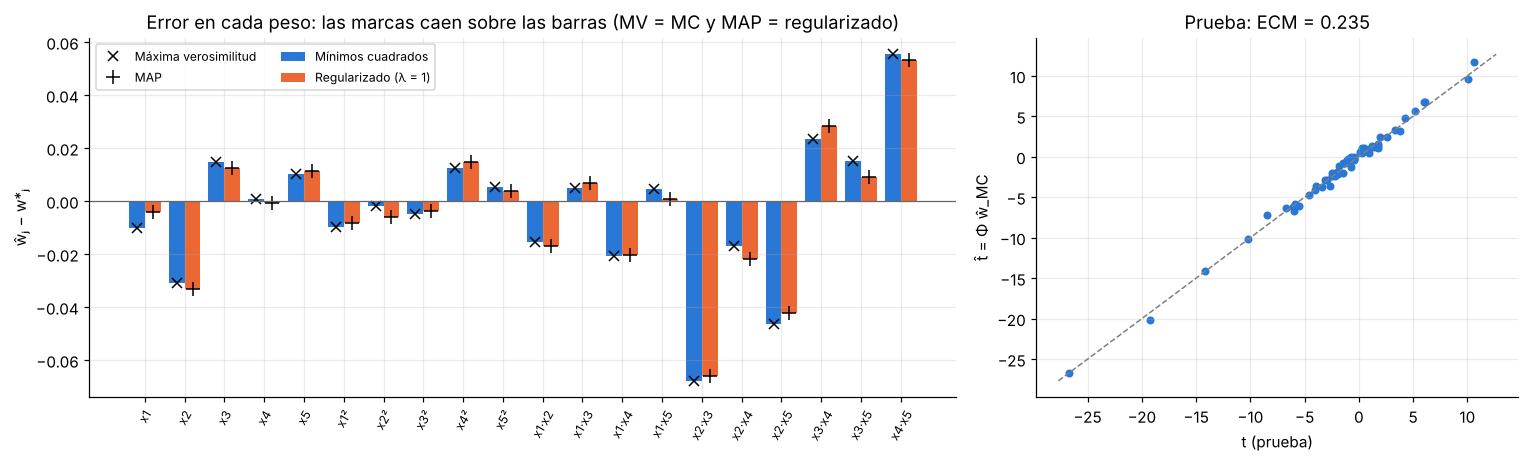

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.3), gridspec_kw={"width_ratios": [1.8, 1]})
k = np.arange(Q)
w_mc, w_r = estimadores[nombres_est[0]], estimadores[nombres_est[1]]
ax[0].bar(k - 0.2, w_mc - w_estrella, 0.4, color=SERIE[0], label="Mínimos cuadrados")
ax[0].bar(k + 0.2, w_r - w_estrella, 0.4, color=SERIE[1], label="Regularizado (λ = 1)")
ax[0].plot(k - 0.2, estimadores[nombres_est[2]] - w_estrella, "x", color="black", ms=7, label="Máxima verosimilitud")
ax[0].plot(k + 0.2, estimadores[nombres_est[3]] - w_estrella, "+", color="black", ms=9, label="MAP")
ax[0].axhline(0, color="0.4", lw=0.8)
ax[0].set_xticks(k, nombres, rotation=60, fontsize=8)
ax[0].set_ylabel("ŵⱼ − w*ⱼ")
ax[0].set_title("Error en cada peso: las marcas caen sobre las barras (MV = MC y MAP = regularizado)")
ax[0].legend(fontsize=8, ncol=2)

t_hat = Phi_pru @ w_mc
lim = [min(t_pru.min(), t_hat.min()) - 1, max(t_pru.max(), t_hat.max()) + 1]
ax[1].plot(lim, lim, "--", color="0.5", lw=1)
ax[1].scatter(t_pru, t_hat, s=18, color=SERIE[0])
ax[1].set_xlabel("t (prueba)"); ax[1].set_ylabel("t̂ = Φ ŵ_MC")
ax[1].set_title(f"Prueba: ECM = {ecm(Phi_pru, t_pru, w_mc):.3f}")
plt.tight_layout(); plt.show()

### Paso 5. Coincidencias y discrepancias

Con la semilla 2026:

- **Mínimos cuadrados y máxima verosimilitud coinciden.** Tienen el mismo ECM de entrenamiento (0.2732), el mismo de prueba (0.2346) y el mismo $\|\hat w-w_*\|_2$ (0.1152). Es lo esperado: la log-verosimilitud es $-\frac{1}{2\sigma_\eta^2}\|t-\Phi w\|^2$ más términos que no dependen de $w$, así que las dos funciones objetivo tienen el mismo minimizador (1.3).
- **El regularizado y el MAP coinciden.** ECM de entrenamiento 0.2734, de prueba 0.2320 y $\|\hat w-w_*\|_2=0.1132$. Con $\sigma_w^2=\sigma_\eta^2/\lambda$ las dos funciones objetivo son proporcionales (1.4).
- **La discrepancia numérica es del orden de $10^{-9}$**, y se explica por cómo se calcula cada uno. `lstsq` y `solve` son métodos directos con error de redondeo cercano a la precisión de la máquina ($10^{-16}$) multiplicada por el número de condición (≈ 4.5). Máxima verosimilitud y MAP se obtienen con un optimizador iterativo (L-BFGS-B), que se detiene cuando el gradiente es casi cero: su tolerancia es la que deja la diferencia de $10^{-9}$. Con una tolerancia más estricta la diferencia baja; nunca llega a ser exactamente 0.
- **Regularizado frente a mínimos cuadrados.** Mínimos cuadrados tiene el menor ECM de entrenamiento, porque es justamente lo que minimiza. Con esta semilla el regularizado queda un poco mejor en prueba y más cerca de $w_*$, pero la diferencia es mínima y en promedio desaparece (paso 7). El problema está bien planteado: hay 240 datos para 20 pesos y el valor singular más pequeño de $\Phi$ es 9.4, así que $\lambda=1$ encoge cada dirección como mucho en un factor $\frac{s^2}{s^2+\lambda}=\frac{89}{90}\approx0.989$.
- **¿Por qué el ECM de prueba es menor que el de entrenamiento?** Por la variabilidad de la muestra. En promedio pasa lo contrario: $\mathbb E[\text{ECM}_{\text{ent}}]=\sigma_\eta^2\frac{N_{\text{ent}}-Q}{N_{\text{ent}}}=0.25\cdot\frac{220}{240}\approx0.229$, y el de prueba es mayor que $\sigma_\eta^2$. Con solo 60 datos de prueba, el ECM de prueba varía bastante de una partición a otra; el paso 7 lo mide repitiendo el experimento.
- **$\hat\sigma^2_{\text{MV}}=0.273$** frente al valor real 0.25: el ruido de esta muestra salió algo mayor que su promedio, y además el estimador de máxima verosimilitud divide entre $N$ y no entre $N-Q$.

### Paso 6. Elección de $\lambda$ con validación cruzada

El «tanteo» con $\lambda$ que mencionó el profesor se hace bien con validación cruzada: se parte el **entrenamiento** en 5 grupos, se ajusta con 4 y se mide el error en el que queda, rotando. El conjunto de prueba no se toca: si se usara para elegir $\lambda$, su error dejaría de ser una estimación honesta del desempeño (fuga de información).

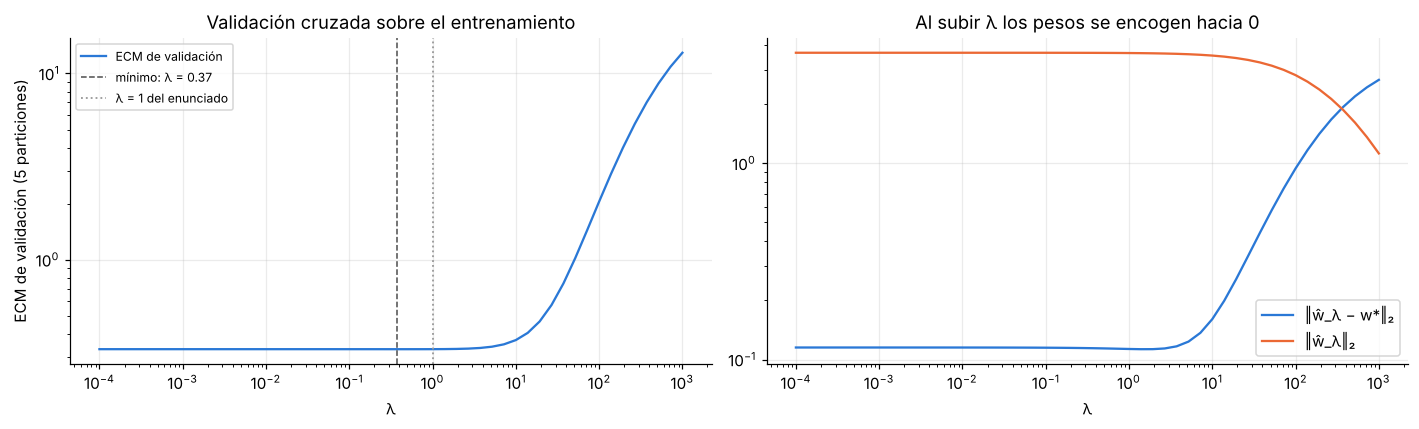

λ elegido por validación cruzada: 0.373
Con ese λ: ECM de prueba = 0.2335   ‖ŵ − w*‖₂ = 0.1143


In [8]:
def validacion_cruzada_ridge(Phi: np.ndarray, t: np.ndarray, lambdas: np.ndarray, k: int,
                             rng: np.random.Generator) -> np.ndarray:
    """ECM promedio de validación para cada λ, con k particiones del entrenamiento. → (len(lambdas),)."""
    particiones = np.array_split(rng.permutation(len(t)), k)
    errores = np.zeros((len(lambdas), k))
    for j, val in enumerate(particiones):
        ajuste = np.setdiff1d(np.arange(len(t)), val)
        for i, lam in enumerate(lambdas):
            errores[i, j] = ecm(Phi[val], t[val], estimador_ridge(Phi[ajuste], t[ajuste], lam))
    return errores.mean(axis=1)


lambdas = np.logspace(-4, 3, 50)
ecm_cv = validacion_cruzada_ridge(Phi_ent, t_ent, lambdas, k=5, rng=np.random.default_rng(SEMILLA))
lam_cv = lambdas[np.argmin(ecm_cv)]
pesos = np.array([estimador_ridge(Phi_ent, t_ent, lam) for lam in lambdas])

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(lambdas, ecm_cv, color=SERIE[0], label="ECM de validación")
ax[0].axvline(lam_cv, color="0.3", ls="--", lw=1, label=f"mínimo: λ = {lam_cv:.2g}")
ax[0].axvline(LAMBDA, color="0.6", ls=":", lw=1.2, label="λ = 1 del enunciado")
ax[0].set_xscale("log"); ax[0].set_yscale("log"); ax[0].legend(fontsize=8)
ax[0].set_xlabel("λ"); ax[0].set_ylabel("ECM de validación (5 particiones)")
ax[0].set_title("Validación cruzada sobre el entrenamiento")
ax[1].plot(lambdas, np.linalg.norm(pesos - w_estrella, axis=1), color=SERIE[0], label="‖ŵ_λ − w*‖₂")
ax[1].plot(lambdas, np.linalg.norm(pesos, axis=1), color=SERIE[1], label="‖ŵ_λ‖₂")
ax[1].set_xscale("log"); ax[1].set_yscale("log"); ax[1].set_xlabel("λ"); ax[1].legend()
ax[1].set_title("Al subir λ los pesos se encogen hacia 0")
plt.tight_layout(); plt.show()

w_cv = estimador_ridge(Phi_ent, t_ent, lam_cv)
print(f"λ elegido por validación cruzada: {lam_cv:.3g}")
print(f"Con ese λ: ECM de prueba = {ecm(Phi_pru, t_pru, w_cv):.4f}   ‖ŵ − w*‖₂ = {np.linalg.norm(w_cv - w_estrella):.4f}")

**Qué dice la validación cruzada.** El mínimo está en $\lambda\approx0.37$, y la curva es casi plana entre $10^{-4}$ y $1$: cualquier $\lambda$ pequeño da prácticamente el mismo error, porque el problema ya está bien condicionado. El valor tiene una lectura bayesiana: en la simulación los pesos reales salen de $\mathcal N(0,1)$, así que el prior «verdadero» tiene $\sigma_w^2=1$ y el $\lambda$ que corresponde a ese prior es $\sigma_\eta^2/\sigma_w^2=0.25$. La validación cruzada encuentra un valor cercano sin conocerlo. Con $\lambda=1$ el MAP supone $\sigma_w^2=0.25$, un prior más estrecho que el real, y encoge los pesos un poco de más.

### Paso 7. ¿Cuánto cambian los números con otra semilla?

Se repite el experimento completo 200 veces, cada vez con datos, pesos, ruido y partición nuevos. Basta con las formas cerradas: máxima verosimilitud y MAP dan lo mismo que mínimos cuadrados y el regularizado, como ya se comprobó.

In [9]:
def repetir_experimento(repeticiones: int, semilla: int) -> pd.DataFrame:
    """ECM de entrenamiento y prueba de mínimos cuadrados y del regularizado en experimentos independientes."""
    filas = []
    for r in range(repeticiones):
        g = np.random.default_rng(semilla + r)
        _, F, y, w_real, _ = generar_datos(g)
        ent, pru = dividir_entrenamiento_prueba(N, FRAC_ENTRENAMIENTO, g)
        for nombre, w in [("Mínimos cuadrados", estimador_mc(F[ent], y[ent])),
                          ("Regularizado (λ = 1)", estimador_ridge(F[ent], y[ent], LAMBDA))]:
            filas.append({"estimador": nombre, "ECM entrenamiento": ecm(F[ent], y[ent], w),
                          "ECM prueba": ecm(F[pru], y[pru], w), "‖ŵ − w*‖₂": np.linalg.norm(w - w_real)})
    return pd.DataFrame(filas)


repeticiones = repetir_experimento(200, SEMILLA + 1000)
display(repeticiones.groupby("estimador").agg(["mean", "std"]))
n_ent = int(FRAC_ENTRENAMIENTO * N)
print(f"Valor teórico de E[ECM de entrenamiento] para mínimos cuadrados: σ²(N_ent − Q)/N_ent = {s2_eta * (n_ent - Q) / n_ent:.4f}")

ECM entrenamiento           ECM prueba            \
                                  mean       std       mean       std   
estimador                                                               
Mínimos cuadrados             0.230601 0.0229319   0.275202 0.0528273   
Regularizado (λ = 1)          0.230958 0.0229415   0.275107 0.0528331   

                     ‖ŵ − w*‖₂            
                          mean       std  
estimador                                 
Mínimos cuadrados     0.144543 0.0236596  
Regularizado (λ = 1)  0.144854 0.0242687

Valor teórico de E[ECM de entrenamiento] para mínimos cuadrados: σ²(N_ent − Q)/N_ent = 0.2292


En 200 repeticiones, el ECM de entrenamiento promedio de mínimos cuadrados es 0.231, muy cerca del valor teórico 0.229, y el de prueba es 0.275, mayor que $\sigma_\eta^2=0.25$. La desviación estándar del ECM de prueba (0.053) es más del doble de la del entrenamiento: con solo 60 datos de prueba, que en una partición salga menor que el de entrenamiento no es raro. El regularizado y mínimos cuadrados quedan prácticamente empatados; en $\|\hat w-w_*\|_2$ el regularizado es apenas peor (0.1449 frente a 0.1445) porque, como se vio en el paso 6, $\lambda=1$ encoge un poco de más.

### Conclusiones del punto 1

- Mínimos cuadrados y máxima verosimilitud dan el mismo estimador cuando el ruido es gaussiano, y el regularizado coincide con el MAP cuando $\lambda=\sigma_\eta^2/\sigma_w^2$. Los números lo confirman hasta la tolerancia del optimizador ($10^{-9}$).
- Sin ruido, el estimador recupera exactamente los pesos verdaderos; con ruido, el error de entrenamiento nunca baja de la energía del ruido.
- En promedio, el ECM de entrenamiento de mínimos cuadrados es $\sigma_\eta^2\frac{N_{\text{ent}}-Q}{N_{\text{ent}}}$ y el de prueba es mayor que $\sigma_\eta^2$: el modelo ajusta un poco del ruido de entrenamiento. Que en la semilla 2026 salga al revés es variabilidad de una partición con solo 60 datos de prueba.
- Con 240 datos para 20 pesos y una matriz bien condicionada, la regularización cambia poco. Su papel se nota cuando $\Phi^\top\Phi$ está mal condicionada o hay más características que datos, y $\lambda$ se debe elegir con validación cruzada, no con el conjunto de prueba.

# Punto 2. Espacios RKHS, embeddings de media y MMD

En los puntos con kernels el enunciado pide distinguir cuatro representaciones:

| Representación | Qué es | Ejemplo en este punto |
|---|---|---|
| Espacio original | Donde viven los datos: $x\in\mathcal X$ | Una imagen como vector de 784 píxeles en $[0,1]$ |
| Espacio de características | Donde vive $\varphi(x)$, con $k(x,x')=\langle\varphi(x),\varphi(x')\rangle$ | Con el kernel gaussiano es de dimensión infinita: $\varphi$ nunca se construye |
| RKHS asociado $\mathcal H_k$ | Espacio de funciones $f:\mathcal X\to\mathbb R$ con la propiedad reproductora $f(x)=\langle f,k(x,\cdot)\rangle$; el mapeo canónico es $\varphi(x)=k(x,\cdot)$ | $\mu_X=\mathbb E[k(X,\cdot)]$ es una función de $\mathcal H_k$ |
| Formulación matricial inducida | Lo que de verdad se calcula: matrices de Gram y vectores de unos | $\mathbf K_{XX}\in\mathbb R^{n\times n}$, $\mathbf K_{XY}\in\mathbb R^{n\times m}$, $\mathbf 1_n^\top\mathbf K_{XX}\mathbf 1_n$ |

> **En clase.** El profesor señaló que 2.1 y 2.2 son las preguntas conceptuales del punto: $\mu_X$ es el valor esperado de $\varphi(X)$, el promedio de los datos después del mapeo.

## 2.1 Definición del embedding de media

Sea $X$ una variable aleatoria en $\mathcal X$ con distribución $P_X$, y $k$ un kernel simétrico, definido positivo y medible, con $\mathbb E\big[\sqrt{k(X,X)}\big]\lt\infty$. Esta condición se cumple siempre que $k$ sea acotado, como el gaussiano, para el que $k(x,x)=1$.

**Definición.** El embedding de media de $P_X$ es el elemento de $\mathcal H_k$

$$\mu_k=\mathbb E[k(X,\cdot)]=\int_{\mathcal X}k(x,\cdot)\,dP_X(x),$$

es decir, el valor esperado del mapeo canónico $\varphi(X)=k(X,\cdot)$. Como $\varphi(X)$ es un elemento aleatorio de un espacio de Hilbert, el valor esperado se entiende como una integral de Bochner. De forma equivalente, $\mu_k$ es el único elemento de $\mathcal H_k$ que cumple

$$\langle f,\mu_k\rangle_{\mathcal H_k}=\mathbb E[f(X)]\qquad\text{para toda }f\in\mathcal H_k .$$

**Evaluación en un punto.** Con $f=k(z,\cdot)$ y la propiedad reproductora, $\mu_k(z)=\langle\mu_k,k(z,\cdot)\rangle=\mathbb E[k(X,z)]$: la similitud promedio de $z$ con la distribución de $X$.

**Versión empírica.** Con una muestra $\{x_i\}_{i=1}^n$, $\hat\mu_k=\frac1n\sum_{i=1}^{n}k(x_i,\cdot)$: el promedio de los puntos $\varphi(x_i)$. Por la ley de los grandes números, $\hat\mu_k\to\mu_k$ cuando $n\to\infty$.

## 2.2 Por qué $\mu_k\in\mathcal H_k$ y qué representa

**Argumento con el teorema de representación de Riesz.** Se define el funcional $T(f)=\mathbb E[f(X)]$ sobre $\mathcal H_k$.

1. *Es lineal*, por la linealidad del valor esperado: $T(af+bg)=aT(f)+bT(g)$.
2. *Es acotado.* Por la propiedad reproductora $f(x)=\langle f,k(x,\cdot)\rangle$ y la desigualdad de Cauchy-Schwarz,
$$|T(f)|\le\mathbb E\,\big|\langle f,k(X,\cdot)\rangle\big|\le\|f\|_{\mathcal H}\ \mathbb E\,\|k(X,\cdot)\|_{\mathcal H}=\|f\|_{\mathcal H}\ \mathbb E\sqrt{k(X,X)}\lt\infty,$$
usando $\|k(x,\cdot)\|^2=\langle k(x,\cdot),k(x,\cdot)\rangle=k(x,x)$.
3. *Riesz:* todo funcional lineal y acotado sobre un espacio de Hilbert es el producto interno con un único elemento del espacio. Ese elemento es $\mu_k$: $T(f)=\langle f,\mu_k\rangle$ con $\mu_k\in\mathcal H_k$.

Otra forma de verlo: $\hat\mu_k$ es una combinación lineal finita de elementos $k(x_i,\cdot)\in\mathcal H_k$, así que está en $\mathcal H_k$; $\mu_k$ es su límite, y también está en $\mathcal H_k$ porque el espacio es completo.

**Interpretación geométrica**

- $\mu_k$ es el **centro de masa** de la nube de puntos $\varphi(x)$ en el RKHS, pesada por $P_X$; $\hat\mu_k$ es el centroide de los $n$ puntos de la muestra.
- Con el kernel lineal $k(x,y)=x^\top y$, $\mu_k$ es la media $\mathbb E[X]$: solo guarda el primer momento. Con un kernel polinómico de grado $d$ guarda los momentos hasta el orden $d$.
- Con un kernel **característico**, como el gaussiano, la correspondencia $P_X\mapsto\mu_k$ es inyectiva: distribuciones distintas tienen embeddings distintos. Por eso $\mu_k$ representa toda la distribución de $X$, no solo su media, y comparar distribuciones se reduce a medir distancias entre puntos de $\mathcal H_k$ (punto 2.3).
- Su norma al cuadrado es la similitud promedio entre dos copias independientes: $\|\mu_k\|^2=\mathbb E[k(X,X')]$.
- Como función, $\mu_k(z)=\mathbb E[k(X,z)]$. Con el kernel gaussiano es una versión suavizada de la densidad de $X$ (un estimador de Parzen sin normalizar).

**Comprobación numérica.** Con el kernel polinómico $k(x,z)=(1+xz)^2$ en una dimensión, el mapeo es finito, $\varphi(x)=[1,\sqrt2x,x^2]$, y el centroide se puede calcular directamente.

In [10]:
def mapeo_polinomico_2(x: np.ndarray) -> np.ndarray:
    """Mapeo explícito del kernel k(x, z) = (1 + xz)² en una dimensión: φ(x) = [1, √2 x, x²]. x: (n,) → (n, 3)."""
    return np.column_stack([np.ones_like(x), np.sqrt(2) * x, x**2])


rng = np.random.default_rng(SEMILLA)
x = rng.normal(1.0, 0.7, 500)
z = np.linspace(-2, 4, 7)

centroide = mapeo_polinomico_2(x).mean(axis=0)              # μ̂ en el espacio de características: (3,)
mu_z_centroide = mapeo_polinomico_2(z) @ centroide           # ⟨μ̂, φ(z)⟩
mu_z_kernel = ((1 + np.outer(z, x))**2).mean(axis=1)        # (1/n) Σ k(x_i, z): sin construir φ
np.testing.assert_allclose(mu_z_centroide, mu_z_kernel)
K = (1 + np.outer(x, x))**2                                   # (n, n)
np.testing.assert_allclose(centroide @ centroide, K.mean())  # ‖μ̂‖² = (1/n²) 1ᵀ K 1

print("μ̂(z) con el centroide: ", np.round(mu_z_centroide, 3))
print("μ̂(z) con el kernel:    ", np.round(mu_z_kernel, 3))
print("El centroide guarda los momentos hasta orden 2:", np.round(centroide, 4))
print("   [1, √2 · media, E[x²]] =                    ", np.round([1, np.sqrt(2) * x.mean(), np.mean(x**2)], 4))

μ̂(z) con el centroide:  [ 3.238  0.537  1.     4.626 11.415 21.367 34.482]
μ̂(z) con el kernel:     [ 3.238  0.537  1.     4.626 11.415 21.367 34.482]
El centroide guarda los momentos hasta orden 2: [1.     1.4454 1.5816]
   [1, √2 · media, E[x²]] =                     [1.     1.4454 1.5816]


Ahora dos distribuciones con **la misma media y la misma varianza** pero distinta forma: una gaussiana y una uniforme. El kernel lineal (primer momento) y el polinómico de grado 2 (hasta el segundo) no las distinguen; el gaussiano sí.

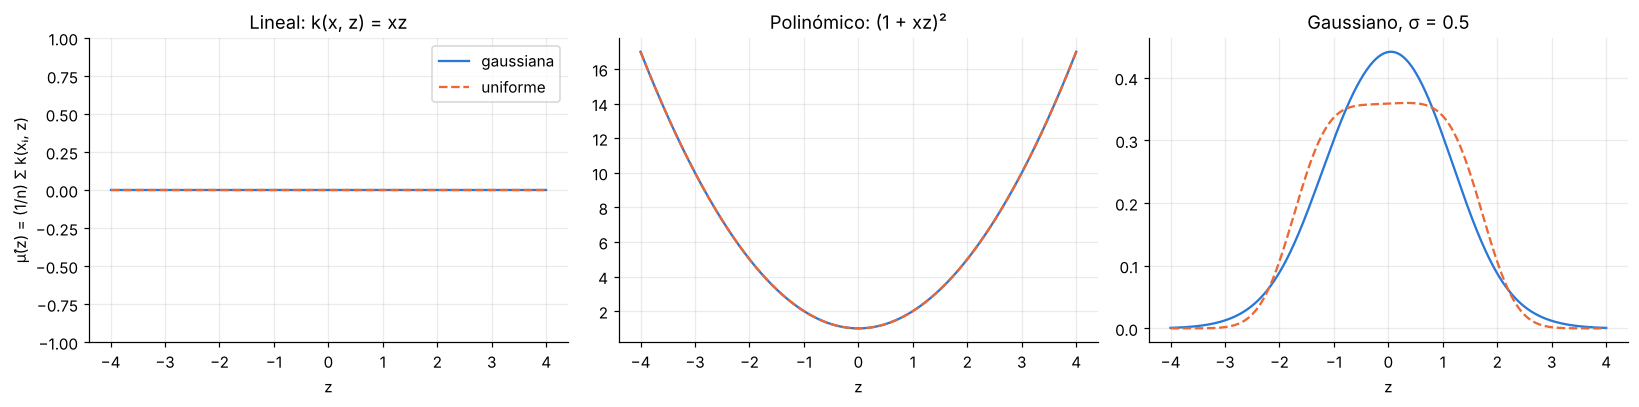

In [11]:
rng = np.random.default_rng(SEMILLA)
estandarizar = lambda v: (v - v.mean()) / v.std()       # media muestral 0 y varianza muestral 1 exactas
a = estandarizar(rng.normal(0.0, 1.0, 4000))            # gaussiana
b = estandarizar(rng.uniform(-1.0, 1.0, 4000))          # uniforme
z = np.linspace(-4, 4, 401)

kernels = {
    "Lineal: k(x, z) = xz": lambda u, v: np.outer(v, u),
    "Polinómico: (1 + xz)²": lambda u, v: (1 + np.outer(v, u))**2,
    "Gaussiano, σ = 0.5": lambda u, v: np.exp(-(v[:, None] - u[None, :])**2 / (2 * 0.5**2)),
}
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for eje, (titulo, k) in zip(ax, kernels.items()):
    eje.plot(z, k(a, z).mean(axis=1), color=SERIE[0], label="gaussiana")
    eje.plot(z, k(b, z).mean(axis=1), color=SERIE[1], ls="--", label="uniforme")
    eje.set_title(titulo); eje.set_xlabel("z")
ax[0].set_ylim(-1, 1)        # las dos medias son 0, así que μ̂(z) = x̄ z = 0 (lo demás sería error de redondeo)
ax[0].set_ylabel("μ̂(z) = (1/n) Σ k(xᵢ, z)"); ax[0].legend()
plt.tight_layout(); plt.show()

## 2.3 MMD: del valor poblacional al estimador sesgado en forma matricial

**Paso 1. Expandir la norma** con la bilinealidad y la simetría del producto interno, como en la ley de cosenos:

$$\operatorname{MMD}^2(P_X,P_Y)=\|\mu_X-\mu_Y\|^2_{\mathcal H_k}=\langle\mu_X,\mu_X\rangle-2\langle\mu_X,\mu_Y\rangle+\langle\mu_Y,\mu_Y\rangle .$$

**Paso 2. Llevar cada producto interno al kernel.** Con $\mu_X=\mathbb E[k(X,\cdot)]$, el valor esperado sale del producto interno por linealidad (la integral de Bochner conmuta con los funcionales lineales y acotados), y la propiedad reproductora $\langle k(x,\cdot),k(y,\cdot)\rangle=k(x,y)$ da

$$\langle\mu_X,\mu_Y\rangle=\big\langle\mathbb E_X[k(X,\cdot)],\ \mathbb E_Y[k(Y,\cdot)]\big\rangle=\mathbb E_{X,Y}\big[\langle k(X,\cdot),k(Y,\cdot)\rangle\big]=\mathbb E_{X,Y}[k(X,Y)] .$$

Igual con los otros dos términos, con $X'$ y $Y'$ copias independientes de $X$ y $Y$:

$$\operatorname{MMD}^2(P_X,P_Y)=\mathbb E_{X,X'}[k(X,X')]-2\,\mathbb E_{X,Y}[k(X,Y)]+\mathbb E_{Y,Y'}[k(Y,Y')] .$$

Esta es la **formulación poblacional**: tres valores esperados que solo se pueden calcular si se conocen $P_X$ y $P_Y$.

**Paso 3. Versión empírica.** Se reemplaza cada embedding por su promedio muestral, $\hat\mu_X=\frac1n\sum_{i=1}^n k(x_i,\cdot)$ y $\hat\mu_Y=\frac1m\sum_{j=1}^m k(y_j,\cdot)$. Por bilinealidad, las sumas salen del producto interno:

$$\langle\hat\mu_X,\hat\mu_X\rangle=\frac{1}{n^2}\sum_{i=1}^{n}\sum_{i'=1}^{n}k(x_i,x_{i'}),\qquad\langle\hat\mu_X,\hat\mu_Y\rangle=\frac{1}{nm}\sum_{i=1}^{n}\sum_{j=1}^{m}k(x_i,y_j),\qquad\langle\hat\mu_Y,\hat\mu_Y\rangle=\frac{1}{m^2}\sum_{j=1}^{m}\sum_{j'=1}^{m}k(y_j,y_{j'}) .$$

**Paso 4. Forma matricial.** Con las matrices de Gram $(\mathbf K_{XX})_{ii'}=k(x_i,x_{i'})$, $(\mathbf K_{XY})_{ij}=k(x_i,y_j)$ y $(\mathbf K_{YY})_{jj'}=k(y_j,y_{j'})$, la suma de todas las entradas de una matriz es $\mathbf 1^\top\mathbf K\mathbf 1$:

$$\sum_{i,i'}k(x_i,x_{i'})=\underbrace{\mathbf 1_n^\top}_{1\times n}\ \underbrace{\mathbf K_{XX}}_{n\times n}\ \underbrace{\mathbf 1_n}_{n\times1},\qquad\sum_{i,j}k(x_i,y_j)=\underbrace{\mathbf 1_n^\top}_{1\times n}\ \underbrace{\mathbf K_{XY}}_{n\times m}\ \underbrace{\mathbf 1_m}_{m\times1}.$$

Al sustituir:

$$\boxed{\widehat{\operatorname{MMD}}{}^2_b=\frac{1}{n^2}\mathbf 1_n^\top\mathbf K_{XX}\mathbf 1_n+\frac{1}{m^2}\mathbf 1_m^\top\mathbf K_{YY}\mathbf 1_m-\frac{2}{nm}\mathbf 1_n^\top\mathbf K_{XY}\mathbf 1_m}$$

**Dimensiones.** Cada término es $(1\times n)(n\times n)(n\times1)=1\times1$, un número. $\mathbf K_{XY}$ es rectangular ($n\times m$) porque compara cada $x_i$ con cada $y_j$; $\mathbf K_{YX}=\mathbf K_{XY}^\top$ da la misma suma, y por eso los dos términos cruzados se juntan en el $-2$.

**Paso 5. Por qué es sesgado.** Las dobles sumas incluyen los términos $i=i'$ y $j=j'$, que comparan cada dato consigo mismo: $k(x_i,x_i)$ no es una muestra de $\mathbb E[k(X,X')]$ con $X'$ independiente. Al tomar el valor esperado,

$$\mathbb E\big[\widehat{\operatorname{MMD}}{}^2_b\big]=\operatorname{MMD}^2+\frac1n\Big(\mathbb E[k(X,X)]-\mathbb E[k(X,X')]\Big)+\frac1m\Big(\mathbb E[k(Y,Y)]-\mathbb E[k(Y,Y')]\Big)\ \ge\ \operatorname{MMD}^2 .$$

Los paréntesis son $\mathbb E\|\varphi(X)-\mu_X\|^2\ge0$, la dispersión de los datos en el espacio de características. El sesgo es positivo, así que el estimador da un valor mayor que 0 incluso si $P_X=P_Y$, y desaparece cuando $n,m\to\infty$. Si se quitan las diagonales se obtiene el estimador insesgado, que puede ser negativo:

$$\widehat{\operatorname{MMD}}{}^2_u=\frac{\mathbf 1_n^\top\mathbf K_{XX}\mathbf 1_n-\operatorname{tr}\mathbf K_{XX}}{n(n-1)}+\frac{\mathbf 1_m^\top\mathbf K_{YY}\mathbf 1_m-\operatorname{tr}\mathbf K_{YY}}{m(m-1)}-\frac{2}{nm}\mathbf 1_n^\top\mathbf K_{XY}\mathbf 1_m .$$

> **Ojo con tus apuntes.** En la fórmula de las notas del 8 de octubre aparece un término de más, $-\frac{2}{MM}\mathbf 1^\top K_{YY}\mathbf 1$. El estimador tiene solo tres términos: los de cada muestra consigo misma, con signo $+$, y el cruzado, $-\frac{2}{nm}\mathbf 1_n^\top\mathbf K_{XY}\mathbf 1_m$.

In [12]:
def distancias_cuadradas(A: np.ndarray, B: np.ndarray) -> np.ndarray:
    """‖a_i − b_j‖² para todas las parejas, sin bucles: z_A 1ᵀ + 1 z_Bᵀ − 2 A Bᵀ.

    A: (n, d), B: (m, d) → (n, m). El redondeo puede dejar valores como −1e−12; se cortan en 0.
    """
    z_a = np.sum(A * A, axis=1)[:, None]          # (n, 1): norma al cuadrado de cada fila de A
    z_b = np.sum(B * B, axis=1)[None, :]          # (1, m)
    return np.maximum(z_a + z_b - 2.0 * A @ B.T, 0.0)


def kernel_gaussiano(A: np.ndarray, B: np.ndarray, sigma: float) -> np.ndarray:
    """Matriz de Gram k(a_i, b_j) = exp(−‖a_i − b_j‖² / (2σ²)). A: (n, d), B: (m, d) → (n, m)."""
    return np.exp(-distancias_cuadradas(A, B) / (2.0 * sigma**2))


def matrices_de_gram(X: np.ndarray, Y: np.ndarray, sigma: float):
    """K_XX: (n, n), K_YY: (m, m) y K_XY: (n, m) con el kernel gaussiano."""
    return kernel_gaussiano(X, X, sigma), kernel_gaussiano(Y, Y, sigma), kernel_gaussiano(X, Y, sigma)


def mmd2_sesgado_gram(K_xx: np.ndarray, K_yy: np.ndarray, K_xy: np.ndarray) -> float:
    """(1/n²) 1ᵀ K_XX 1 + (1/m²) 1ᵀ K_YY 1 − (2/nm) 1ᵀ K_XY 1, escrito tal como en la fórmula."""
    n, m = K_xy.shape
    uno_n, uno_m = np.ones(n), np.ones(m)
    return float(uno_n @ K_xx @ uno_n / n**2 + uno_m @ K_yy @ uno_m / m**2 - 2.0 * uno_n @ K_xy @ uno_m / (n * m))


def mmd2_insesgado_gram(K_xx: np.ndarray, K_yy: np.ndarray, K_xy: np.ndarray) -> float:
    """Estimador insesgado: quita la diagonal de K_XX y K_YY (cada dato comparado consigo mismo)."""
    n, m = K_xy.shape
    return float((K_xx.sum() - np.trace(K_xx)) / (n * (n - 1)) + (K_yy.sum() - np.trace(K_yy)) / (m * (m - 1))
                 - 2.0 * K_xy.sum() / (n * m))


def mmd2_sesgado(X: np.ndarray, Y: np.ndarray, sigma: float) -> float:
    """MMD² sesgado entre las muestras X: (n, d) e Y: (m, d) con el kernel gaussiano de ancho σ."""
    return mmd2_sesgado_gram(*matrices_de_gram(X, Y, sigma))

In [13]:
rng = np.random.default_rng(SEMILLA)
A, B = rng.normal(0.0, 1.0, (30, 4)), rng.normal(0.5, 1.0, (20, 4))
s = 1.3

# 1) Distancias sin bucles = doble bucle
D_bucle = np.array([[np.sum((a - b)**2) for b in B] for a in A])
np.testing.assert_allclose(distancias_cuadradas(A, B), D_bucle, atol=1e-10)

# 2) La forma matricial da lo mismo que las tres dobles sumatorias del paso 3
k = lambda u, v: np.exp(-np.sum((u - v)**2) / (2 * s**2))
sumatorias = (sum(k(u, v) for u in A for v in A) / len(A)**2
              + sum(k(u, v) for u in B for v in B) / len(B)**2
              - 2 * sum(k(u, v) for u in A for v in B) / (len(A) * len(B)))
np.testing.assert_allclose(mmd2_sesgado(A, B, s), sumatorias)

# 3) Con un kernel de mapeo finito, ‖μ̂_X − μ̂_Y‖² calculado en el espacio de características es la forma matricial
x1, y1 = rng.normal(0, 1, 40), rng.normal(0.3, 1.2, 25)
diferencia_centroides = mapeo_polinomico_2(x1).mean(0) - mapeo_polinomico_2(y1).mean(0)
k_pol = lambda u, v: (1 + np.outer(u, v))**2
np.testing.assert_allclose(diferencia_centroides @ diferencia_centroides,
                           mmd2_sesgado_gram(k_pol(x1, x1), k_pol(y1, y1), k_pol(x1, y1)))

K_xx, K_yy, K_xy = matrices_de_gram(A, B, s)
print(f"Dimensiones con n = {len(A)}, m = {len(B)}:  K_XX {K_xx.shape}   K_YY {K_yy.shape}   K_XY {K_xy.shape}")
print("Todas las pruebas pasaron.")

Dimensiones con n = 30, m = 20:  K_XX (30, 30)   K_YY (20, 20)   K_XY (30, 20)
Todas las pruebas pasaron.


**El sesgo, medido.** Se toman muestras $X$ y $Y$ de la **misma** distribución, así que $\operatorname{MMD}^2=0$, y se promedia el estimador sobre muchas repeticiones para varios tamaños $n=m$. El sesgado se queda por encima de 0, tal como predice el paso 5; el insesgado se centra en 0.

,sesgado,insesgado,sesgo teórico
n = m,,,
10,0.134078,-0.000356536,0.134399
20,0.0645424,-0.00224242,0.0666727
50,0.0261759,-0.00046026,0.0266269
100,0.0126518,-0.000647513,0.0132929
200,0.00655592,-0.000110471,0.00666584


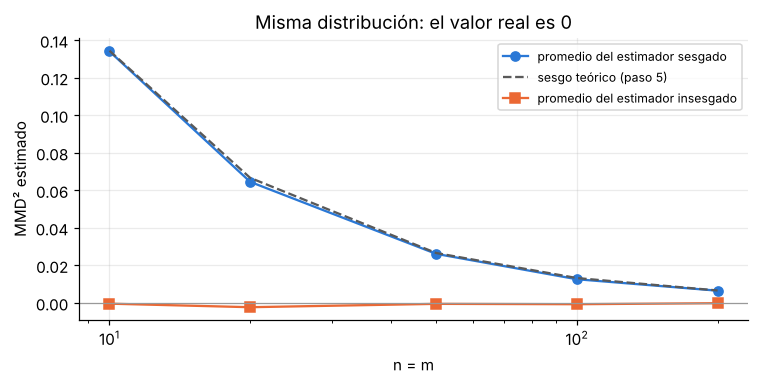

In [14]:
rng = np.random.default_rng(SEMILLA)
tamanos, repeticiones, s = [10, 20, 50, 100, 200], 200, 1.0
promedios = {"sesgado": [], "insesgado": [], "sesgo teórico": []}
for n in tamanos:
    b_vals, u_vals, kxx_cruzado = [], [], []
    for _ in range(repeticiones):
        Xs, Ys = rng.standard_normal((n, 2)), rng.standard_normal((n, 2))
        K_xx, K_yy, K_xy = matrices_de_gram(Xs, Ys, s)
        b_vals.append(mmd2_sesgado_gram(K_xx, K_yy, K_xy))
        u_vals.append(mmd2_insesgado_gram(K_xx, K_yy, K_xy))
        kxx_cruzado.append(K_xy.mean())                  # estima E[k(X, X')] con X, X' independientes
    promedios["sesgado"].append(np.mean(b_vals))
    promedios["insesgado"].append(np.mean(u_vals))
    promedios["sesgo teórico"].append(2 / n * (1 - np.mean(kxx_cruzado)))   # (1/n + 1/m)(k(x,x) − E k(X,X'))

display(pd.DataFrame(promedios, index=pd.Index(tamanos, name="n = m")))
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(tamanos, promedios["sesgado"], "o-", color=SERIE[0], label="promedio del estimador sesgado")
ax.plot(tamanos, promedios["sesgo teórico"], "--", color="0.35", label="sesgo teórico (paso 5)")
ax.plot(tamanos, promedios["insesgado"], "s-", color=SERIE[1], label="promedio del estimador insesgado")
ax.axhline(0, color="0.6", lw=0.8)
ax.set_xscale("log"); ax.set_xlabel("n = m"); ax.set_ylabel("MMD² estimado"); ax.legend(fontsize=8)
ax.set_title("Misma distribución: el valor real es 0")
plt.tight_layout(); plt.show()

## 2.4 Implementación con MNIST y Fashion-MNIST

Plan, según el enunciado:

1. De cada dataset, 1000 imágenes del conjunto de entrenamiento elegidas con una semilla fija y partidas al azar en dos grupos disjuntos de 500. Cada imagen de $28\times28$ se convierte en un vector de 784 componentes en $[0,1]$.
2. Un solo $\sigma$ para todas las comparaciones, con la heurística de la mediana sobre la muestra combinada (las 2000 imágenes elegidas).
3. $\widehat{\operatorname{MMD}}{}^2_b$ entre MNIST y Fashion-MNIST (primer grupo de cada uno, $n=m=500$) y, como referencia, entre los dos grupos de MNIST y entre los dos de Fashion-MNIST. No se usan etiquetas.
4. Análisis: ancho de banda, variabilidad muestral y una prueba de permutaciones.

> **En clase.** El profesor pidió partir las imágenes en dos grupos disjuntos de 500 y recordó el código de la matriz kernel entre dos matrices distintas: compara cada fila de una con cada fila de la otra, que es $\mathbf K_{XY}$, de $n\times m$.

**Expresión utilizada:** $\widehat{\operatorname{MMD}}{}^2_b=\frac{1}{n^2}\mathbf 1_n^\top\mathbf K_{XX}\mathbf 1_n+\frac{1}{m^2}\mathbf 1_m^\top\mathbf K_{YY}\mathbf 1_m-\frac{2}{nm}\mathbf 1_n^\top\mathbf K_{XY}\mathbf 1_m$, con $k(u,v)=\exp\!\big(-\|u-v\|_2^2/(2\sigma^2)\big)$.

In [15]:
URL_IDX = {
    "mnist": "https://raw.githubusercontent.com/fgnt/mnist/master/",
    "fashion": "https://raw.githubusercontent.com/zalandoresearch/fashion-mnist/master/data/fashion/",
}


def leer_idx(ruta: str) -> np.ndarray:
    """Lee un archivo IDX comprimido, el formato original de MNIST, como arreglo de uint8."""
    with gzip.open(ruta, "rb") as f:
        datos = f.read()
    assert datos[2] == 0x08, "se esperaba un archivo de tipo uint8"
    ndim = datos[3]
    forma = np.frombuffer(datos[4:4 + 4 * ndim], dtype=">u4").astype(int)
    return np.frombuffer(datos[4 + 4 * ndim:], dtype=np.uint8).reshape(forma)


def cargar_entrenamiento(nombre: str, carpeta: str = "datos") -> tuple[np.ndarray, np.ndarray]:
    """Imágenes de entrenamiento (60000, 28, 28) en uint8 y sus etiquetas (60000,).

    nombre: "mnist" o "fashion". Usa Keras si está instalado (Colab). Si no, descarga los
    archivos originales desde GitHub la primera vez y los guarda en `carpeta`.
    """
    try:
        from tensorflow.keras import datasets
        (imagenes, etiquetas), _ = (datasets.mnist if nombre == "mnist" else datasets.fashion_mnist).load_data()
        return imagenes, etiquetas
    except Exception as error:                      # sin TensorFlow o sin acceso a sus servidores
        print(f"{nombre}: Keras no está disponible ({type(error).__name__}); se usan los archivos de GitHub.")
    os.makedirs(carpeta, exist_ok=True)
    partes = []
    for archivo in ("train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz"):
        ruta = os.path.join(carpeta, f"{nombre}_{archivo}")
        if not os.path.exists(ruta):
            urllib.request.urlretrieve(URL_IDX[nombre] + archivo, ruta)
        partes.append(leer_idx(ruta))
    return partes[0], partes[1]


def seleccionar_y_dividir(imagenes: np.ndarray, total: int, tam_grupo: int, rng: np.random.Generator):
    """Elige `total` imágenes sin reemplazo y las parte en dos grupos disjuntos de `tam_grupo`.

    imagenes: (60000, 28, 28) en uint8 → A, B: (tam_grupo, 784) con valores en [0, 1], y los índices elegidos.
    """
    indices = rng.permutation(rng.choice(len(imagenes), size=total, replace=False))   # orden aleatorio
    vectores = imagenes[indices].reshape(total, -1).astype(np.float64) / 255.0       # 28 × 28 → 784, en [0, 1]
    return vectores[:tam_grupo], vectores[tam_grupo:2 * tam_grupo], indices


def sigma_mediana(Z: np.ndarray) -> float:
    """Heurística de la mediana: σ = mediana de ‖z_i − z_j‖ sobre todas las parejas i < j. Z: (N, d)."""
    D = distancias_cuadradas(Z, Z)
    i, j = np.triu_indices(len(Z), k=1)
    return float(np.median(np.sqrt(D[i, j])))

mnist: Keras no está disponible (ModuleNotFoundError); se usan los archivos de GitHub.


fashion: Keras no está disponible (ModuleNotFoundError); se usan los archivos de GitHub.


MNIST: (60000, 28, 28), uint8    Fashion-MNIST: (60000, 28, 28), uint8
Grupos: MNIST A (500, 784), MNIST B (500, 784), Fashion A (500, 784), Fashion B (500, 784); valores entre 0.0 y 1.0


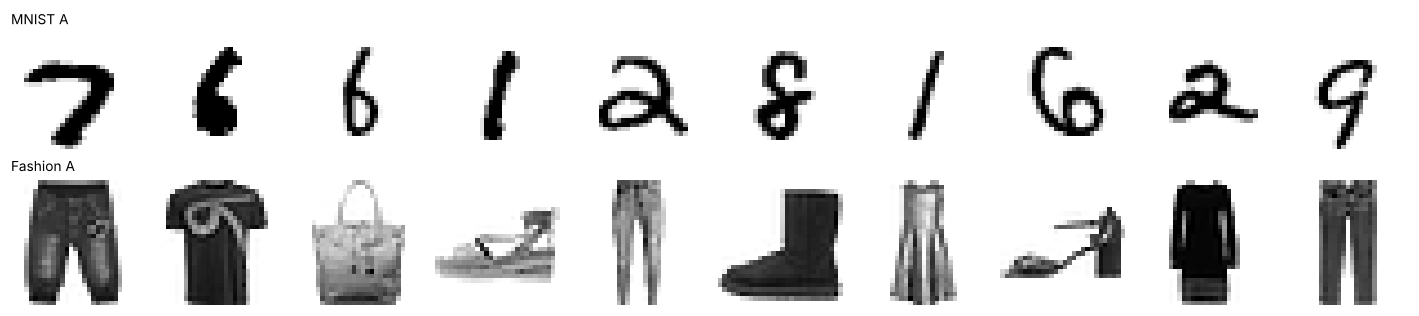

In [16]:
img_mnist, etq_mnist = cargar_entrenamiento("mnist")
img_fashion, etq_fashion = cargar_entrenamiento("fashion")
print(f"MNIST: {img_mnist.shape}, {img_mnist.dtype}    Fashion-MNIST: {img_fashion.shape}, {img_fashion.dtype}")

rng = np.random.default_rng(SEMILLA)
M_A, M_B, idx_mnist = seleccionar_y_dividir(img_mnist, N_IMAGENES, N_GRUPO, rng)
F_A, F_B, idx_fashion = seleccionar_y_dividir(img_fashion, N_IMAGENES, N_GRUPO, rng)
assert len(set(idx_mnist[:N_GRUPO]) & set(idx_mnist[N_GRUPO:])) == 0      # grupos disjuntos
print(f"Grupos: MNIST A {M_A.shape}, MNIST B {M_B.shape}, Fashion A {F_A.shape}, Fashion B {F_B.shape}; "
      f"valores entre {M_A.min()} y {M_A.max()}")

fig, ax = plt.subplots(2, 10, figsize=(13, 2.9))
for j in range(10):
    ax[0, j].imshow(M_A[j].reshape(28, 28), cmap="gray_r", vmin=0, vmax=1)
    ax[1, j].imshow(F_A[j].reshape(28, 28), cmap="gray_r", vmin=0, vmax=1)
for a in ax.flat:
    a.axis("off")
ax[0, 0].set_title("MNIST A", loc="left", fontsize=9); ax[1, 0].set_title("Fashion A", loc="left", fontsize=9)
plt.tight_layout(); plt.show()

In [17]:
Z = np.vstack([M_A, M_B, F_A, F_B])                 # muestra combinada: (2000, 784)
SIGMA_MMD = sigma_mediana(Z)                        # el mismo σ para las tres comparaciones
print(f"σ (mediana de las distancias entre las 2000 imágenes) = {SIGMA_MMD:.3f}")

comparaciones = {
    "MNIST A vs Fashion A": (M_A, F_A),
    "MNIST A vs MNIST B": (M_A, M_B),
    "Fashion A vs Fashion B": (F_A, F_B),
}
filas = {}
for nombre, (A, B) in comparaciones.items():
    K_xx, K_yy, K_xy = matrices_de_gram(A, B, SIGMA_MMD)
    filas[nombre] = {"K_XX": K_xx.shape, "K_YY": K_yy.shape, "K_XY": K_xy.shape,
                     "(1/n²) 1ᵀK_XX 1": K_xx.mean(), "(1/m²) 1ᵀK_YY 1": K_yy.mean(), "(1/nm) 1ᵀK_XY 1": K_xy.mean(),
                     "MMD² sesgado": mmd2_sesgado_gram(K_xx, K_yy, K_xy),
                     "MMD² insesgado": mmd2_insesgado_gram(K_xx, K_yy, K_xy)}
tabla_mmd = pd.DataFrame(filas).T
display(tabla_mmd)
print(f"Límite del estimador sesgado cuando σ → 0 (K → I): 1/n + 1/m = {1 / N_GRUPO + 1 / N_GRUPO:.4f}")

σ (mediana de las distancias entre las 2000 imágenes) = 11.096


,K_XX,K_YY,K_XY,(1/n²) 1ᵀK_XX 1,(1/m²) 1ᵀK_YY 1,(1/nm) 1ᵀK_XY 1,MMD² sesgado,MMD² insesgado
MNIST A vs Fashion A,"(500, 500)","(500, 500)","(500, 500)",0.66258,0.589822,0.558754,0.134893,0.133395
MNIST A vs MNIST B,"(500, 500)","(500, 500)","(500, 500)",0.66258,0.661702,0.661638,0.00100538,-0.000348769
Fashion A vs Fashion B,"(500, 500)","(500, 500)","(500, 500)",0.589822,0.596466,0.592483,0.00132215,-0.000308537


Límite del estimador sesgado cuando σ → 0 (K → I): 1/n + 1/m = 0.0040


**Influencia del ancho de banda.** Se recalcula el MMD² de las tres comparaciones para $\sigma$ entre $0.05$ y $10$ veces el de la mediana. Las distancias se calculan una sola vez: solo cambia la exponencial.

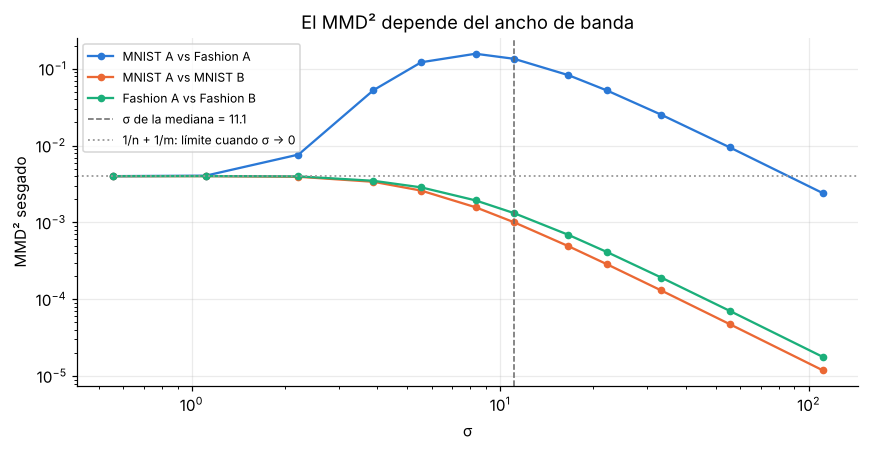

σ,0.55,1.11,2.22,3.88,5.55,8.32,11.1,16.64,22.19,33.29,55.48,110.96
MNIST A vs Fashion A,0.00400612,0.00405978,0.00764802,0.0526695,0.121694,0.156993,0.134893,0.0826624,0.0522341,0.0252592,0.00949884,0.00241903
MNIST A vs MNIST B,0.0040006,0.00400916,0.00393297,0.00338392,0.00259706,0.00157775,0.00100538,0.000491129,0.000285872,0.000130244,4.74924e-05,1.19378e-05
Fashion A vs Fashion B,0.00400586,0.00401203,0.00397724,0.0034852,0.00286113,0.00193747,0.00132215,0.000689546,0.000412336,0.000191795,7.07176e-05,1.7861e-05


In [18]:
factores = np.array([0.05, 0.1, 0.2, 0.35, 0.5, 0.75, 1, 1.5, 2, 3, 5, 10])
distancias = {nombre: (distancias_cuadradas(A, A), distancias_cuadradas(B, B), distancias_cuadradas(A, B))
              for nombre, (A, B) in comparaciones.items()}
curvas = {nombre: [mmd2_sesgado_gram(*[np.exp(-D / (2 * (f * SIGMA_MMD)**2)) for D in Ds]) for f in factores]
          for nombre, Ds in distancias.items()}

fig, ax = plt.subplots(figsize=(8, 4.2))
for (nombre, valores), color in zip(curvas.items(), SERIE):
    ax.plot(factores * SIGMA_MMD, valores, "o-", color=color, ms=4, label=nombre)
ax.axvline(SIGMA_MMD, color="0.4", ls="--", lw=1, label=f"σ de la mediana = {SIGMA_MMD:.1f}")
ax.axhline(2 / N_GRUPO, color="0.6", ls=":", lw=1.2, label="1/n + 1/m: límite cuando σ → 0")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("σ"); ax.set_ylabel("MMD² sesgado"); ax.legend(fontsize=8)
ax.set_title("El MMD² depende del ancho de banda")
plt.tight_layout(); plt.show()
display(pd.DataFrame(curvas, index=pd.Index(np.round(factores * SIGMA_MMD, 2), name="σ")).T)

**Variabilidad muestral.** Se repite toda la selección (1000 imágenes por dataset, dos grupos de 500) con 20 semillas distintas, manteniendo el mismo $\sigma$.

,mean,std,min,max
MNIST A vs Fashion A,0.127673,0.00759983,0.111121,0.140372
MNIST A vs MNIST B,0.00137247,0.000254885,0.00102487,0.00210978
Fashion A vs Fashion B,0.00153086,0.000503759,0.000873906,0.00311656


(1.6 s)


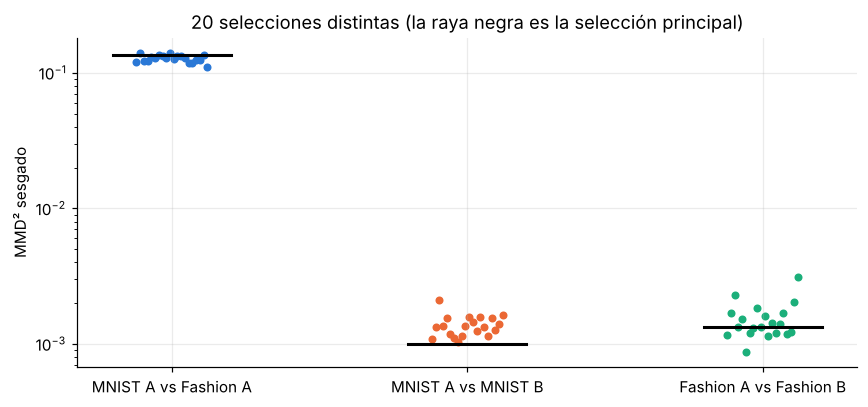

In [19]:
def repetir_comparaciones(img_x: np.ndarray, img_y: np.ndarray, repeticiones: int, sigma: float,
                          semilla: int) -> pd.DataFrame:
    """MMD² sesgado de las tres comparaciones con selecciones independientes de imágenes.

    img_x, img_y: imágenes de MNIST y de Fashion-MNIST, (60000, 28, 28). → una fila por repetición.
    """
    filas = []
    for r in range(repeticiones):
        g = np.random.default_rng(semilla + r)
        a, b, _ = seleccionar_y_dividir(img_x, N_IMAGENES, N_GRUPO, g)
        c, d, _ = seleccionar_y_dividir(img_y, N_IMAGENES, N_GRUPO, g)
        filas.append({"MNIST A vs Fashion A": mmd2_sesgado(a, c, sigma),
                      "MNIST A vs MNIST B": mmd2_sesgado(a, b, sigma),
                      "Fashion A vs Fashion B": mmd2_sesgado(c, d, sigma)})
    return pd.DataFrame(filas)


t0 = time.perf_counter()
variabilidad = repetir_comparaciones(img_mnist, img_fashion, 20, SIGMA_MMD, SEMILLA + 100)
display(variabilidad.agg(["mean", "std", "min", "max"]).T)
print(f"({time.perf_counter() - t0:.1f} s)")

fig, ax = plt.subplots(figsize=(8, 3.8))
for j, (nombre, color) in enumerate(zip(variabilidad.columns, SERIE)):
    ax.scatter(np.full(len(variabilidad), j) + np.linspace(-0.12, 0.12, len(variabilidad)),
               variabilidad[nombre], color=color, s=18)
    ax.plot([j - 0.2, j + 0.2], [tabla_mmd.loc[nombre, "MMD² sesgado"]] * 2, color="black", lw=2)
ax.set_xticks(range(3), variabilidad.columns)
ax.set_yscale("log"); ax.set_ylabel("MMD² sesgado")
ax.set_title("20 selecciones distintas (la raya negra es la selección principal)")
plt.tight_layout(); plt.show()

**Contraste de hipótesis con permutaciones.** Hipótesis nula: $P_X=P_Y$. Si fuera cierta, las etiquetas «grupo $X$» y «grupo $Y$» serían intercambiables. Se mezclan las $n+m$ imágenes, se reparten al azar en dos grupos de los mismos tamaños y se recalcula el MMD²; repitiéndolo se obtiene la distribución del estadístico bajo $H_0$. El p-valor es la fracción de permutaciones con un MMD² mayor o igual al observado. La matriz kernel de las $n+m$ imágenes se calcula una sola vez: cada permutación solo reordena sus bloques.

,MMD² observado,media bajo H0,p-valor
MNIST A vs Fashion A,0.134893,0.00158521,0.00497512
MNIST A vs MNIST B,0.00100538,0.00138117,0.910448
Fashion A vs Fashion B,0.00132215,0.00164039,0.626866


200 permutaciones por comparación (2.9 s). El p-valor más pequeño posible es 1/201 = 0.0050.


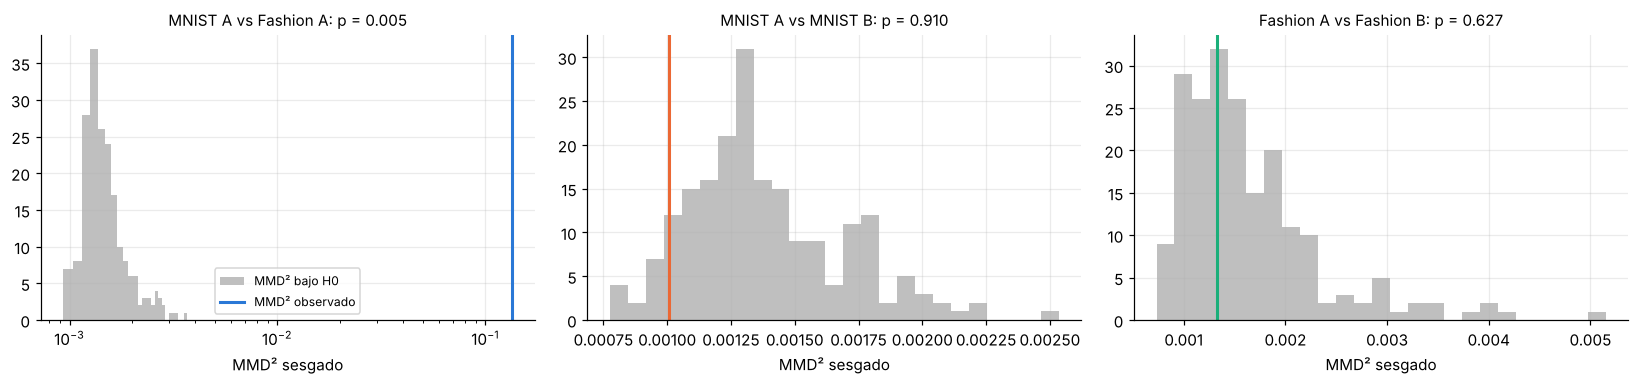

In [20]:
def prueba_permutacion(X: np.ndarray, Y: np.ndarray, sigma: float, permutaciones: int,
                       rng: np.random.Generator):
    """Prueba de H0: P_X = P_Y con el MMD² sesgado. → (observado, p-valor, valores bajo H0)."""
    W = np.vstack([X, Y])                                     # (n + m, d)
    n = len(X)
    K = kernel_gaussiano(W, W, sigma)                         # (n + m, n + m), una sola vez

    def estadistico(orden):
        a, b = orden[:n], orden[n:]
        return mmd2_sesgado_gram(K[np.ix_(a, a)], K[np.ix_(b, b)], K[np.ix_(a, b)])

    observado = estadistico(np.arange(len(W)))
    nulos = np.array([estadistico(rng.permutation(len(W))) for _ in range(permutaciones)])
    p_valor = (1 + np.sum(nulos >= observado)) / (1 + permutaciones)
    return observado, p_valor, nulos


B_PERM = 200
t0 = time.perf_counter()
pruebas = {nombre: prueba_permutacion(A, B, SIGMA_MMD, B_PERM, np.random.default_rng(SEMILLA))
           for nombre, (A, B) in comparaciones.items()}
display(pd.DataFrame({nombre: {"MMD² observado": obs, "media bajo H0": nul.mean(), "p-valor": p}
                      for nombre, (obs, p, nul) in pruebas.items()}).T)
print(f"{B_PERM} permutaciones por comparación ({time.perf_counter() - t0:.1f} s). "
      f"El p-valor más pequeño posible es 1/{B_PERM + 1} = {1 / (B_PERM + 1):.4f}.")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
for eje, (nombre, (obs, p, nul)), color in zip(ax, pruebas.items(), SERIE):
    eje.hist(nul, bins=25, color="0.75", label="MMD² bajo H0")
    eje.axvline(obs, color=color, lw=2, label="MMD² observado")
    eje.set_title(f"{nombre}: p = {p:.3f}", fontsize=10); eje.set_xlabel("MMD² sesgado")
    if obs > 5 * nul.max():
        eje.set_xscale("log")
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Conclusiones del punto 2.4

Con la semilla 2026, $\sigma=11.10$ (mediana de las distancias entre las 2000 imágenes) y $n=m=500$:

| Comparación | MMD² sesgado | p-valor |
|---|---|---|
| MNIST A vs Fashion A | 0.135 | el mínimo posible con 200 permutaciones |
| MNIST A vs MNIST B | 0.0010 | grande: no hay evidencia de diferencia |
| Fashion A vs Fashion B | 0.0013 | grande: no hay evidencia de diferencia |

- **MNIST y Fashion-MNIST son distribuciones distintas.** Su MMD² es unas 100 veces el de las comparaciones dentro de cada dataset. La tabla muestra de dónde sale: la similitud promedio entre una imagen de MNIST y una de Fashion ($\frac{1}{nm}\mathbf 1^\top\mathbf K_{XY}\mathbf 1=0.559$) es menor que la de dos imágenes de MNIST (0.663) y que la de dos de Fashion (0.590), y el MMD² suma esas diferencias: $0.663+0.590-2(0.559)=0.135$.
- **Dentro de un mismo dataset el MMD² sesgado no es 0, pero casi todo es sesgo.** Con $k(x,x)=1$, el sesgo del paso 5 es $\big(\frac1n+\frac1m\big)\big(1-\mathbb E[k(X,X')]\big)$, del orden de $10^{-3}$ aquí, y el estimador insesgado queda cerca de 0 (ligeramente negativo).
- **Ancho de banda.** Con $\sigma\to0$, $\mathbf K\to\mathbf I$: todas las comparaciones dan $\frac1n+\frac1m=0.004$ y el MMD no distingue nada. Con $\sigma\to\infty$, $\mathbf K\to\mathbf 1\mathbf 1^\top$: todo se parece a todo y el MMD tiende a 0. Entre esos extremos, el MMD² entre MNIST y Fashion-MNIST es máximo con $\sigma\approx8.3$, cerca del $\sigma$ de la mediana (11.1), y las comparaciones dentro de cada dataset quedan siempre muy por debajo. Un valor de MMD² solo se puede comparar con otro calculado con el mismo $\sigma$, el mismo kernel y los mismos tamaños.
- **Variabilidad muestral.** Al cambiar la selección de imágenes, el MMD² entre datasets varía alrededor de un 6 % (0.128 ± 0.008) y los de dentro de cada dataset varían del orden de $10^{-4}$. La brecha entre los dos casos es mucho mayor que esa variación.
- **Límites de un valor suelto.** Un MMD² por sí solo no dice si la diferencia es real: su escala depende de $\sigma$, de $n$ y $m$ y del sesgo, y no tiene un umbral universal. Para concluir hace falta un contraste formal, como la prueba de permutaciones: el p-valor dice qué tan raro sería el valor observado si las dos muestras vinieran de la misma distribución. Además, la resolución del p-valor depende del número de permutaciones, y probar muchos $\sigma$ para quedarse con el que da el p-valor más pequeño invalida la prueba: el $\sigma$ se fija antes, como aquí con la mediana.

### Comprobación extra de la clase: ¿el 1 se parece al 7?

En clase el profesor anticipó que, al comparar dígitos, el 0 se parecería al 6 y que el 1 «sí o sí» se parecería al 7, porque hay quien escribe el 7 casi como un 1. En las notas quedó como «2.4: relación de implementación, $1_X\to7_Y$». Esta comprobación **usa las etiquetas**, así que no es parte de las comparaciones que pide el enunciado: se toman 200 imágenes de cada dígito de MNIST, con el mismo $\sigma$.

Similitud promedio entre 1 y 7:    K̄_17 = 0.695  (puesto 4 de 45 entre las más parecidas)
Similitud dentro del 1 y del 7:    K̄_11 = 0.839   K̄_77 = 0.738
MMD²(1, 7) = K̄_11 + K̄_77 − 2 K̄_17 = 0.187  (puesto 38 de 45 de menor a mayor)
Parejas con menor MMD²: 4–9 (0.040), 5–8 (0.058), 3–5 (0.062), 7–9 (0.064)
Píxeles encendidos por imagen, en promedio: {0: 195, 1: 85, 2: 168, 3: 163, 4: 141, 5: 152, 6: 154, 7: 135, 8: 174, 9: 142}


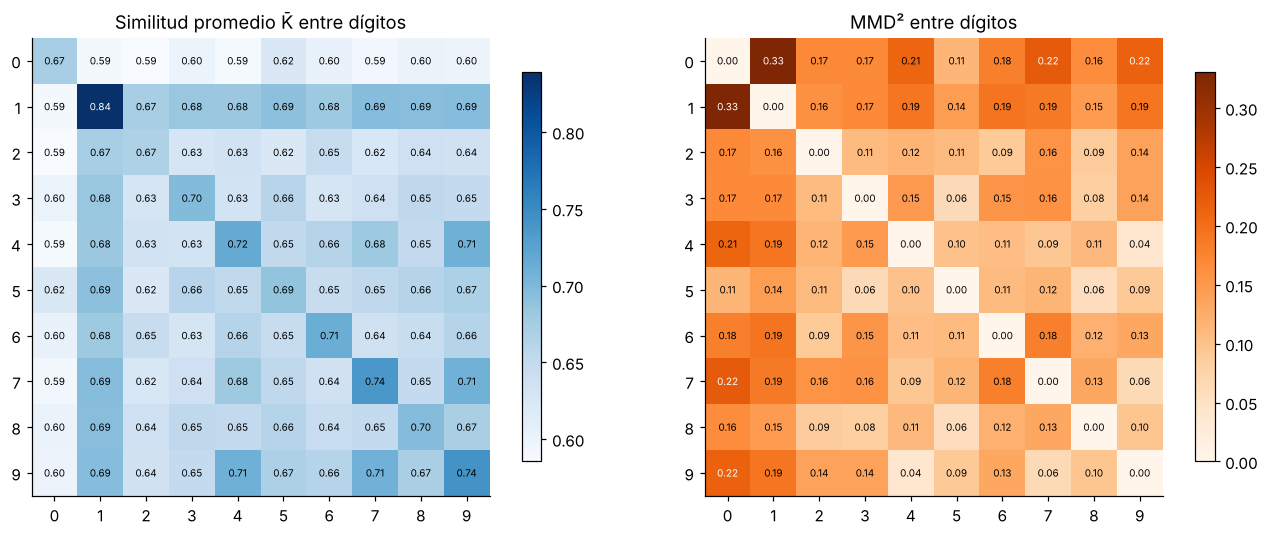

In [21]:
rng = np.random.default_rng(SEMILLA)
por_clase = 200
X_clases = np.vstack([img_mnist[rng.choice(np.flatnonzero(etq_mnist == c), por_clase, replace=False)]
                      .reshape(por_clase, -1) / 255.0 for c in range(10)])              # (2000, 784), ordenadas por dígito
K = kernel_gaussiano(X_clases, X_clases, SIGMA_MMD)
K_medio = K.reshape(10, por_clase, 10, por_clase).mean(axis=(1, 3))     # (10, 10): promedio de cada bloque
MMD_clases = np.diag(K_medio)[:, None] + np.diag(K_medio)[None, :] - 2 * K_medio   # K̄_aa + K̄_bb − 2 K̄_ab

parejas = [(a, b) for a in range(10) for b in range(a + 1, 10)]
puesto = lambda valores, par, mayor_primero: sorted(parejas, key=lambda p: valores[p], reverse=mayor_primero).index(par) + 1
pixeles = (X_clases > 0).sum(axis=1).reshape(10, por_clase).mean(axis=1)

print(f"Similitud promedio entre 1 y 7:    K̄_17 = {K_medio[1, 7]:.3f}  "
      f"(puesto {puesto(K_medio, (1, 7), True)} de 45 entre las más parecidas)")
print(f"Similitud dentro del 1 y del 7:    K̄_11 = {K_medio[1, 1]:.3f}   K̄_77 = {K_medio[7, 7]:.3f}")
print(f"MMD²(1, 7) = K̄_11 + K̄_77 − 2 K̄_17 = {MMD_clases[1, 7]:.3f}  "
      f"(puesto {puesto(MMD_clases, (1, 7), False)} de 45 de menor a mayor)")
print("Parejas con menor MMD²:", ", ".join(f"{a}–{b} ({MMD_clases[a, b]:.3f})"
                                           for a, b in sorted(parejas, key=lambda p: MMD_clases[p])[:4]))
print("Píxeles encendidos por imagen, en promedio:", {c: round(v) for c, v in enumerate(pixeles)})

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.8))
for eje, M, titulo, mapa in [(ax[0], K_medio, "Similitud promedio K̄ entre dígitos", "Blues"),
                             (ax[1], MMD_clases, "MMD² entre dígitos", "Oranges")]:
    im = eje.imshow(M, cmap=mapa)
    for (i, j), v in np.ndenumerate(M):
        eje.text(j, i, f"{v:.2f}", ha="center", va="center", fontsize=6.5,
                 color="white" if v > M.min() + 0.65 * (M.max() - M.min()) else "black")
    eje.set_xticks(range(10)); eje.set_yticks(range(10)); eje.grid(False)
    eje.set_title(titulo); fig.colorbar(im, ax=eje, shrink=0.85)
plt.tight_layout(); plt.show()

**Qué muestra.** Las dos cosas son ciertas a la vez, y la diferencia es justamente lo que mide el MMD:

- En la **matriz kernel**, el 1 y el 7 sí están entre las parejas más parecidas: $\bar K_{17}\approx0.70$, en el puesto 4 de 45. Es lo que se ve al mirar los bloques de la matriz, como dijo el profesor.
- Pero el 1 se parece casi igual a muchos otros dígitos (al 5, al 8, al 9). Los unos tienen pocos píxeles encendidos (unos 85, frente a 135 a 195 de los demás dígitos), y una imagen con poca tinta queda a poca distancia euclidiana de casi cualquier otra.
- El **MMD** resta la similitud interna: $\operatorname{MMD}^2(1,7)=\bar K_{11}+\bar K_{77}-2\bar K_{17}$. Los unos son muy parecidos entre sí ($\bar K_{11}\approx0.84$, el valor más alto de la diagonal), así que, como distribuciones, el 1 queda lejos de todos los dígitos. Las parejas más cercanas por MMD son 4–9, 5–8, 3–5 y 7–9.

En resumen: que dos imágenes se parezcan en promedio ($\bar K_{ab}$ alto) no basta para que sus distribuciones se parezcan; el MMD compara la similitud cruzada con la similitud de cada grupo consigo mismo.

# Punto 3. Índice de correlación de Pearson: espacio original y RKHS

## 3.1 Coeficiente de Pearson en el espacio original

**Paso 1. De valores esperados a promedios muestrales.** Con $N$ observaciones emparejadas $(x_n,y_n)$, cada valor esperado se estima con un promedio:

$$\hat\mu_X=\bar x=\frac1N\sum_{n=1}^N x_n,\qquad \widehat{\mathbb E}[(X-\mu_X)(Y-\mu_Y)]=\frac1N\sum_{n=1}^N(x_n-\bar x)(y_n-\bar y),$$

así que

$$\hat\rho_{XY}=\frac{\frac1N\sum_n(x_n-\bar x)(y_n-\bar y)}{\sqrt{\frac1N\sum_n(x_n-\bar x)^2\ \cdot\ \frac1N\sum_n(y_n-\bar y)^2}} .$$

Los factores $\frac1N$ se cancelan (también si se usa $\frac1{N-1}$).

**Paso 2. La media en forma matricial.** $\bar x=\frac1N\mathbf 1_N^\top\mathbf x$ es un escalar, y el vector con la media repetida es $\bar x\,\mathbf 1_N=\frac1N\mathbf 1_N\mathbf 1_N^\top\mathbf x$, de $N\times1$.

**Paso 3. Centrado con $\mathbf H$.**

$$\mathbf x-\bar x\,\mathbf 1_N=\mathbf x-\frac1N\mathbf 1_N\mathbf 1_N^\top\mathbf x=\Big(\mathbf I_N-\frac1N\mathbf 1_N\mathbf 1_N^\top\Big)\mathbf x=\mathbf H\mathbf x .$$

**Paso 4. Propiedades de $\mathbf H$** ($N\times N$). Es simétrica, $\mathbf H^\top=\mathbf H$, e idempotente, $\mathbf H^2=\mathbf H$ (centrar dos veces es centrar una vez):

$$\mathbf H^2=\mathbf I-\frac2N\mathbf 1\mathbf 1^\top+\frac{1}{N^2}\mathbf 1\underbrace{\mathbf 1^\top\mathbf 1}_{=N}\mathbf 1^\top=\mathbf I-\frac1N\mathbf 1\mathbf 1^\top=\mathbf H .$$

**Paso 5. Sumatorias como productos internos.**

$$\sum_{n=1}^N(x_n-\bar x)(y_n-\bar y)=(\mathbf H\mathbf x)^\top(\mathbf H\mathbf y)=\mathbf x^\top\mathbf H^\top\mathbf H\mathbf y=\mathbf x^\top\mathbf H\mathbf y,$$

y del mismo modo $\sum_n(x_n-\bar x)^2=\mathbf x^\top\mathbf H\mathbf x$ y $\sum_n(y_n-\bar y)^2=\mathbf y^\top\mathbf H\mathbf y$.

**Paso 6. Resultado.**

$$\boxed{\hat\rho_{XY}=\frac{\mathbf x^\top\mathbf H\mathbf y}{\sqrt{(\mathbf x^\top\mathbf H\mathbf x)(\mathbf y^\top\mathbf H\mathbf y)}}}$$

**Dimensiones.** $\mathbf x^\top\mathbf H\mathbf y$ es $(1\times N)(N\times N)(N\times1)=1\times1$: un número. Por eso el resultado no es una matriz: $\mathbf x$ y $\mathbf y$ son vectores de una sola variable. Con matrices de datos de varias columnas, $\mathbf X^\top\mathbf H\mathbf Y$ sí sería una matriz, la de covarianzas cruzadas. Geométricamente, $\hat\rho_{XY}$ es el coseno del ángulo entre los vectores centrados $\mathbf H\mathbf x$ y $\mathbf H\mathbf y$.

> **En tus notas del 8 de octubre:** «3.1: ¿por qué no da una matriz?». La respuesta está en las dimensiones: $(1\times N)(N\times N)(N\times1)=1\times1$. En NumPy, con vectores columna de forma `(N, 1)`, `x.T @ H @ y` devuelve un arreglo de forma `(1, 1)`, y `.item()` lo convierte en número.

In [22]:
def matriz_centrado(n: int) -> np.ndarray:
    """H = I_N − (1/N) 1 1ᵀ: (N, N)."""
    return np.eye(n) - np.ones((n, n)) / n


def pearson_matricial(x: np.ndarray, y: np.ndarray) -> float:
    """ρ̂ = xᵀHy / √((xᵀHx)(yᵀHy)) con x, y vectores columna (N, 1), como en el enunciado."""
    assert x.ndim == 2 and x.shape[1] == 1 and x.shape == y.shape, "x e y deben tener forma (N, 1)"
    H = matriz_centrado(len(x))
    numerador = x.T @ H @ y                                  # (1, N)(N, N)(N, 1) = (1, 1)
    denominador = np.sqrt((x.T @ H @ x) * (y.T @ H @ y))     # (1, 1)
    return (numerador / denominador).item()                  # de matriz 1×1 a número


rng = np.random.default_rng(SEMILLA)
N3 = 200
x = rng.standard_normal((N3, 1))
y = 0.6 * x + 0.8 * rng.standard_normal((N3, 1))
H = matriz_centrado(N3)

np.testing.assert_allclose(H, H.T)                                   # simétrica
np.testing.assert_allclose(H @ H, H, atol=1e-12)                     # idempotente
np.testing.assert_allclose(H @ np.ones(N3), 0, atol=1e-12)           # centra: H 1 = 0
np.testing.assert_allclose(H @ x, x - x.mean(), atol=1e-12)          # Hx es x menos su media
rho = pearson_matricial(x, y)
np.testing.assert_allclose(rho, np.corrcoef(x.ravel(), y.ravel())[0, 1])

print(f"x: {x.shape}   H: {H.shape}   xᵀHy: {(x.T @ H @ y).shape}  ← una matriz 1×1, es decir, un número")
print(f"ρ̂ con la forma matricial = {rho:.6f}    np.corrcoef = {np.corrcoef(x.ravel(), y.ravel())[0, 1]:.6f}")

x: (200, 1)   H: (200, 200)   xᵀHy: (1, 1)  ← una matriz 1×1, es decir, un número
ρ̂ con la forma matricial = 0.656459    np.corrcoef = 0.656459


## 3.2 Correlación matricial en el RKHS: alineamiento centrado de kernels

**Paso 1. Producto interno entre matrices (Frobenius).** Para $\mathbf A,\mathbf B\in\mathbb R^{N\times N}$:

$$\langle\mathbf A,\mathbf B\rangle_F=\sum_{i=1}^N\sum_{j=1}^N A_{ij}B_{ij}=\operatorname{tr}(\mathbf A^\top\mathbf B),\qquad\|\mathbf A\|_F=\sqrt{\langle\mathbf A,\mathbf A\rangle_F}.$$

La igualdad con la traza sale de que el elemento $j$ de la diagonal de $\mathbf A^\top\mathbf B$ es $\sum_i A_{ij}B_{ij}$; al sumar la diagonal aparece la doble sumatoria.

**Paso 2. Matrices de Gram centradas.** $\mathbf K_{X,c}=\mathbf H\mathbf K_X\mathbf H$ y $\mathbf K_{Y,c}=\mathbf H\mathbf K_Y\mathbf H$ son las matrices de productos internos de los datos centrados en el espacio de características: $(\mathbf K_{X,c})_{ij}=\langle\varphi_X(x_i)-\hat\mu_X,\ \varphi_X(x_j)-\hat\mu_X\rangle$. Son simétricas: $(\mathbf H\mathbf K\mathbf H)^\top=\mathbf H^\top\mathbf K^\top\mathbf H^\top=\mathbf H\mathbf K\mathbf H$.

**Paso 3. Producto interno normalizado**, es decir, el coseno entre las dos matrices centradas:

$$\rho_{\text{RKHS}}(\mathbf K_X,\mathbf K_Y)=\frac{\langle\mathbf K_{X,c},\mathbf K_{Y,c}\rangle_F}{\|\mathbf K_{X,c}\|_F\,\|\mathbf K_{Y,c}\|_F}=\frac{\sum_{i,j}(\mathbf K_{X,c})_{ij}(\mathbf K_{Y,c})_{ij}}{\sqrt{\sum_{i,j}(\mathbf K_{X,c})_{ij}^2\ \sum_{i,j}(\mathbf K_{Y,c})_{ij}^2}} .$$

**Paso 4. De sumatorias a trazas.** Como $\mathbf K_{X,c}$ es simétrica y $\mathbf H\mathbf H=\mathbf H$,

$$\langle\mathbf K_{X,c},\mathbf K_{Y,c}\rangle_F=\operatorname{tr}(\mathbf K_{X,c}^\top\mathbf K_{Y,c})=\operatorname{tr}(\mathbf H\mathbf K_X\mathbf H\mathbf H\mathbf K_Y\mathbf H)=\operatorname{tr}(\mathbf H\mathbf K_X\mathbf H\mathbf K_Y\mathbf H).$$

Por la propiedad cíclica de la traza, $\operatorname{tr}(\mathbf A\mathbf B\mathbf C)=\operatorname{tr}(\mathbf C\mathbf A\mathbf B)$, la última $\mathbf H$ pasa al frente, se junta con la primera ($\mathbf H\mathbf H=\mathbf H$), y luego la primera pasa al final:

$$\operatorname{tr}(\mathbf H\mathbf K_X\mathbf H\mathbf K_Y\mathbf H)=\operatorname{tr}(\mathbf H\mathbf K_X\mathbf H\mathbf K_Y)=\operatorname{tr}(\mathbf K_X\mathbf H\mathbf K_Y\mathbf H).$$

Igual para las normas: $\|\mathbf K_{X,c}\|_F^2=\operatorname{tr}(\mathbf K_X\mathbf H\mathbf K_X\mathbf H)$ y $\|\mathbf K_{Y,c}\|_F^2=\operatorname{tr}(\mathbf K_Y\mathbf H\mathbf K_Y\mathbf H)$.

**Paso 5. Resultado.**

$$\boxed{\rho_{\text{RKHS}}(\mathbf K_X,\mathbf K_Y)=\frac{\operatorname{tr}(\mathbf K_X\mathbf H\mathbf K_Y\mathbf H)}{\sqrt{\operatorname{tr}(\mathbf K_X\mathbf H\mathbf K_X\mathbf H)\ \operatorname{tr}(\mathbf K_Y\mathbf H\mathbf K_Y\mathbf H)}}}$$

**Dimensiones.** $\mathbf K_X,\mathbf K_Y,\mathbf H\in\mathbb R^{N\times N}$, así que $\mathbf K_X\mathbf H\mathbf K_Y\mathbf H$ es $N\times N$ y su traza es un número. Que $X\in\mathbb R^P$ y $Y\in\mathbb R^Q$ tengan dimensiones distintas no importa: las dos matrices de Gram son $N\times N$ porque comparan las mismas $N$ observaciones. Como $\mathbf K_{X,c}$ y $\mathbf K_{Y,c}$ son semidefinidas positivas, el numerador es $\ge0$ y $\rho_{\text{RKHS}}\in[0,1]$.

**Las cuatro representaciones.** Espacio original: $x_n\in\mathbb R^P$ y $y_n\in\mathbb R^Q$. Espacio de características: $\varphi_X(x_n)$ y $\varphi_Y(y_n)$. RKHS: $\mathcal H_{k_X}$ y $\mathcal H_{k_Y}$, con $(\mathbf K_X)_{ij}=k_X(x_i,x_j)=\langle\varphi_X(x_i),\varphi_X(x_j)\rangle$. Formulación matricial: el cociente de trazas, que solo necesita las dos matrices $N\times N$.

**Paso 6. Kernels lineales con $P=Q=1$.** Con $k_X(x,x')=xx'$ y $k_Y(y,y')=yy'$ se tiene $\mathbf K_X=\mathbf x\mathbf x^\top$ y $\mathbf K_Y=\mathbf y\mathbf y^\top$, matrices $N\times N$ de rango 1. Entonces

$$\operatorname{tr}(\mathbf K_X\mathbf H\mathbf K_Y\mathbf H)=\operatorname{tr}(\mathbf x\mathbf x^\top\mathbf H\mathbf y\mathbf y^\top\mathbf H)=\operatorname{tr}\big(\mathbf y^\top\mathbf H\mathbf x\ \mathbf x^\top\mathbf H\mathbf y\big)=(\mathbf x^\top\mathbf H\mathbf y)^2,$$

usando la propiedad cíclica para dejar dentro de la traza un producto $1\times1$, y que $\mathbf y^\top\mathbf H\mathbf x=\mathbf x^\top\mathbf H\mathbf y$ (es un escalar y $\mathbf H$ es simétrica). Del mismo modo, $\operatorname{tr}(\mathbf K_X\mathbf H\mathbf K_X\mathbf H)=(\mathbf x^\top\mathbf H\mathbf x)^2$ y $\operatorname{tr}(\mathbf K_Y\mathbf H\mathbf K_Y\mathbf H)=(\mathbf y^\top\mathbf H\mathbf y)^2$. Así,

$$\rho_{\text{RKHS}}=\frac{(\mathbf x^\top\mathbf H\mathbf y)^2}{\sqrt{(\mathbf x^\top\mathbf H\mathbf x)^2(\mathbf y^\top\mathbf H\mathbf y)^2}}=\frac{(\mathbf x^\top\mathbf H\mathbf y)^2}{(\mathbf x^\top\mathbf H\mathbf x)(\mathbf y^\top\mathbf H\mathbf y)}=\hat\rho_{XY}^{\,2},$$

donde se usó que $\mathbf x^\top\mathbf H\mathbf x=\|\mathbf H\mathbf x\|^2\ge0$, así que la raíz de su cuadrado es el mismo número.

**Por qué se pierde el signo.** La matriz de Gram lineal no cambia si $\mathbf x\to-\mathbf x$: $(-\mathbf x)(-\mathbf x)^\top=\mathbf x\mathbf x^\top$. La matriz de Gram solo guarda las similitudes entre parejas de observaciones, no la orientación de cada variable. Por eso $\rho_{\text{RKHS}}$ mide qué tan fuerte es la relación, no su dirección: $\hat\rho_{XY}=0.9$ y $\hat\rho_{XY}=-0.9$ dan el mismo $\rho_{\text{RKHS}}=0.81$.

In [23]:
def centrar_gram(K: np.ndarray) -> np.ndarray:
    """H K H: (N, N)."""
    H = matriz_centrado(len(K))
    return H @ K @ H


def alineamiento_centrado(K_x: np.ndarray, K_y: np.ndarray) -> float:
    """ρ_RKHS = tr(K_x H K_y H) / √(tr(K_x H K_x H) · tr(K_y H K_y H)), con K_x, K_y: (N, N)."""
    H = matriz_centrado(len(K_x))
    numerador = np.trace(K_x @ H @ K_y @ H)
    denominador = np.sqrt(np.trace(K_x @ H @ K_x @ H) * np.trace(K_y @ H @ K_y @ H))
    return float(numerador / denominador)


def alineamiento_frobenius(K_x: np.ndarray, K_y: np.ndarray) -> float:
    """El mismo índice como coseno entre las matrices centradas: ⟨K_xc, K_yc⟩_F / (‖K_xc‖_F ‖K_yc‖_F)."""
    A, B = centrar_gram(K_x), centrar_gram(K_y)
    return float(np.sum(A * B) / (np.linalg.norm(A) * np.linalg.norm(B)))


def kernel_lineal(A: np.ndarray, B: np.ndarray) -> np.ndarray:
    """k(a, b) = aᵀb para todas las parejas. A: (n, d), B: (m, d) → (n, m)."""
    return A @ B.T


# 1) La forma con trazas da lo mismo que la doble sumatoria (Frobenius)
Kx, Ky = kernel_gaussiano(x, x, 1.0), kernel_gaussiano(y, y, 1.0)
np.testing.assert_allclose(alineamiento_centrado(Kx, Ky), alineamiento_frobenius(Kx, Ky))

# 2) Kernels lineales con P = Q = 1: ρ_RKHS = ρ̂²
Kx_lin, Ky_lin = kernel_lineal(x, x), kernel_lineal(y, y)          # x xᵀ e y yᵀ: (N, N), de rango 1
np.testing.assert_allclose(alineamiento_centrado(Kx_lin, Ky_lin), pearson_matricial(x, y)**2)

# 3) El signo se pierde: con −y, ρ̂ cambia de signo y ρ_RKHS no cambia
np.testing.assert_allclose(kernel_lineal(-y, -y), Ky_lin)
print(f"ρ̂(x, y) = {pearson_matricial(x, y):+.4f}    ρ̂(x, −y) = {pearson_matricial(x, -y):+.4f}")
print(f"ρ_RKHS lineal con y = {alineamiento_centrado(Kx_lin, Ky_lin):.4f}    "
      f"con −y = {alineamiento_centrado(Kx_lin, kernel_lineal(-y, -y)):.4f}    ρ̂² = {pearson_matricial(x, y)**2:.4f}")
print("Todas las pruebas pasaron.")

ρ̂(x, y) = +0.6565    ρ̂(x, −y) = -0.6565
ρ_RKHS lineal con y = 0.4309    con −y = 0.4309    ρ̂² = 0.4309
Todas las pruebas pasaron.


**Qué gana el RKHS.** Tres relaciones con $N=200$: lineal positiva, lineal negativa y $y=x^2$ más ruido, que es una dependencia fuerte pero no lineal. Para el kernel gaussiano se usa la heurística de la mediana en cada variable.

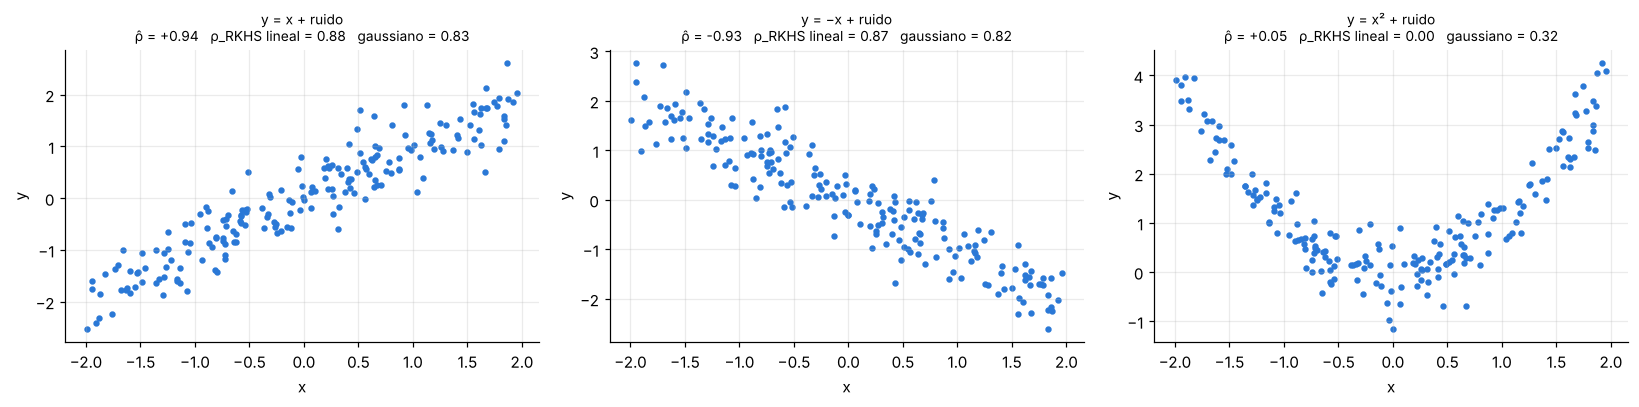

,ρ̂ (Pearson),ρ̂²,ρ_RKHS lineal,ρ_RKHS gaussiano
y = x + ruido,0.936772,0.877541,0.877541,0.834454
y = −x + ruido,-0.931871,0.868384,0.868384,0.822571
y = x² + ruido,0.0491216,0.00241293,0.00241293,0.318572


In [24]:
rng = np.random.default_rng(SEMILLA)
x = rng.uniform(-2, 2, (N3, 1))
relaciones = {
    "y = x + ruido": x + 0.4 * rng.standard_normal((N3, 1)),
    "y = −x + ruido": -x + 0.4 * rng.standard_normal((N3, 1)),
    "y = x² + ruido": x**2 + 0.4 * rng.standard_normal((N3, 1)),
}
filas = {}
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for eje, (nombre, yy) in zip(ax, relaciones.items()):
    K_gx, K_gy = kernel_gaussiano(x, x, sigma_mediana(x)), kernel_gaussiano(yy, yy, sigma_mediana(yy))
    filas[nombre] = {"ρ̂ (Pearson)": pearson_matricial(x, yy),
                     "ρ̂²": pearson_matricial(x, yy)**2,
                     "ρ_RKHS lineal": alineamiento_centrado(kernel_lineal(x, x), kernel_lineal(yy, yy)),
                     "ρ_RKHS gaussiano": alineamiento_centrado(K_gx, K_gy)}
    eje.scatter(x, yy, s=10, color=SERIE[0])
    f = filas[nombre]
    eje.set_title(f"{nombre}\nρ̂ = {f['ρ̂ (Pearson)']:+.2f}   ρ_RKHS lineal = {f['ρ_RKHS lineal']:.2f}   "
                  f"gaussiano = {f['ρ_RKHS gaussiano']:.2f}", fontsize=9)
    eje.set_xlabel("x"); eje.set_ylabel("y")
plt.tight_layout(); plt.show()
display(pd.DataFrame(filas).T)

También funciona con variables vectoriales de distinta dimensión: $X\in\mathbb R^{3}$ y $Y\in\mathbb R^{2}$, con $Y$ dependiente de $X$ o independiente. Las dos matrices de Gram son $200\times200$ aunque $P\ne Q$.

In [25]:
rng = np.random.default_rng(SEMILLA)
Xv = rng.standard_normal((N3, 3))                                          # P = 3
Y_dep = np.column_stack([np.sin(Xv[:, 0]) + Xv[:, 1]**2, Xv[:, 2] * Xv[:, 0]]) + 0.1 * rng.standard_normal((N3, 2))
Y_ind = rng.standard_normal((N3, 2))                                       # Q = 2, independiente de X
tabla = {}
for nombre, Yv in [("Y depende de X", Y_dep), ("Y independiente de X", Y_ind)]:
    K_x, K_y = kernel_gaussiano(Xv, Xv, sigma_mediana(Xv)), kernel_gaussiano(Yv, Yv, sigma_mediana(Yv))
    tabla[nombre] = {"K_X": K_x.shape, "K_Y": K_y.shape,
                     "ρ_RKHS lineal": alineamiento_centrado(kernel_lineal(Xv, Xv), kernel_lineal(Yv, Yv)),
                     "ρ_RKHS gaussiano": alineamiento_centrado(K_x, K_y)}
display(pd.DataFrame(tabla).T)

,K_X,K_Y,ρ_RKHS lineal,ρ_RKHS gaussiano
Y depende de X,"(200, 200)","(200, 200)",0.112815,0.294901
Y independiente de X,"(200, 200)","(200, 200)",0.00725871,0.026798


### Conclusiones del punto 3

- El coeficiente de Pearson muestral es $\frac{\mathbf x^\top\mathbf H\mathbf y}{\sqrt{(\mathbf x^\top\mathbf H\mathbf x)(\mathbf y^\top\mathbf H\mathbf y)}}$: centrar es multiplicar por $\mathbf H$, y cada sumatoria es un producto interno de vectores centrados. Es un número porque $\mathbf x$ y $\mathbf y$ son vectores $N\times1$.
- El alineamiento centrado aplica la misma idea a matrices: el coseno entre $\mathbf H\mathbf K_X\mathbf H$ y $\mathbf H\mathbf K_Y\mathbf H$ con el producto interno de Frobenius, escrito con trazas.
- Con kernels lineales en una dimensión es $\hat\rho_{XY}^2$: mide la fuerza de la relación lineal y pierde el signo, porque $\mathbf x\mathbf x^\top$ no cambia al cambiar $\mathbf x$ por $-\mathbf x$.
- Con el kernel gaussiano detecta dependencias no lineales que Pearson no ve (en $y=x^2$, $\hat\rho\approx0$) y compara variables de distinta dimensión. Es la idea detrás de HSIC y CKA, que se usan para medir dependencia entre variables y para comparar representaciones de redes neuronales.

# Resumen

| Punto | Resultado principal |
|---|---|
| 1.1 | $\hat w_{\text{MC}}=(\Phi^\top\Phi)^{-1}\Phi^\top t$; única si $\operatorname{rango}(\Phi)=Q$; si no, la de norma mínima es $\Phi^+t$ |
| 1.2 | $\hat w_\lambda=(\Phi^\top\Phi+\lambda I)^{-1}\Phi^\top t$; siempre única con $\lambda\gt0$; encoge las direcciones con valores singulares pequeños |
| 1.3 | Con ruido gaussiano, máxima verosimilitud = mínimos cuadrados; $\hat\sigma^2=\frac1N\|t-\Phi\hat w\|^2$ |
| 1.4 | MAP = regularizado con $\lambda=\sigma_\eta^2/\sigma_w^2$ |
| 1.5 | MC y MV coinciden, igual que el regularizado y MAP, hasta $10^{-9}$ (tolerancia del optimizador). Sin ruido, $\hat w=w_*$ exacto |
| 2.1 y 2.2 | $\mu_k=\mathbb E[k(X,\cdot)]\in\mathcal H_k$ por Riesz; es el centro de masa de los datos en el RKHS y, con un kernel característico, representa toda la distribución |
| 2.3 | $\widehat{\operatorname{MMD}}{}^2_b=\frac{1}{n^2}\mathbf 1^\top\mathbf K_{XX}\mathbf 1+\frac{1}{m^2}\mathbf 1^\top\mathbf K_{YY}\mathbf 1-\frac{2}{nm}\mathbf 1^\top\mathbf K_{XY}\mathbf 1$, con sesgo positivo de orden $\frac1n+\frac1m$ |
| 2.4 | MMD² = 0.135 entre MNIST y Fashion-MNIST frente a ≈ 0.001 dentro de cada dataset; la prueba de permutaciones confirma la diferencia |
| 3.1 | $\hat\rho_{XY}=\frac{\mathbf x^\top\mathbf H\mathbf y}{\sqrt{(\mathbf x^\top\mathbf H\mathbf x)(\mathbf y^\top\mathbf H\mathbf y)}}$ |
| 3.2 | $\rho_{\text{RKHS}}=\frac{\operatorname{tr}(\mathbf K_X\mathbf H\mathbf K_Y\mathbf H)}{\sqrt{\operatorname{tr}(\mathbf K_X\mathbf H\mathbf K_X\mathbf H)\operatorname{tr}(\mathbf K_Y\mathbf H\mathbf K_Y\mathbf H)}}$; con kernels lineales en 1D es $\hat\rho^2$ |